# Computational Linear Algebra: PCA Homework

#### Initialization:
Fill the missing values in this text box and in the following code-cell.

**Academic Year:** 2024/2025

### Team Members (Alphabetical Order):
1. Ghezzi, Lucia (325951);
2. Paradiso, Giuliana (319688).

In [1]:
StudentID1 = 325951  # <-------- Fill in the missing value
StudentID2 = 319688  # <-------- Fill in the missing value

## Starting Code-Cell 
### Attention: DO NOT CHANGE THE CODE INSIDE THE FOLLOWING CELL!

In [2]:
####################################################################
############## DO NOT CHANGE THE CODE IN THIS CELL #################
####################################################################

import numpy as np

var_entertainment_feat_types = ['Interests', 'Movies', 'Music']
var_personal_feat_types = ['Finance', 'Phobias']
fixed_feat_types = ['Personality', 'Health']

label_types = ['Demographic']

variables_by_type = {
    'Demographics': ['Age', 'Height', 'Weight', 'Number of siblings', 
                     'Gender', 'Hand', 'Education', 'Only child', 'Home Town Type',
                     'Home Type'],
    'Finance': ['Finances', 'Shopping centres', 'Branded clothing', 
                'Entertainment spending', 'Spending on looks', 
                'Spending on gadgets', 'Spending on healthy eating'],
    'Health': ['Smoking', 'Alcohol', 'Healthy eating'],
    'Interests': ['History', 'Psychology', 'Politics', 'Mathematics', 
                  'Physics', 'Internet', 'PC', 'Economy Management', 
                  'Biology', 'Chemistry', 'Reading', 'Geography', 
                  'Foreign languages', 'Medicine', 'Law', 'Cars', 
                  'Art exhibitions', 'Religion', 'Countryside, outdoors', 
                  'Dancing', 'Musical instruments', 'Writing', 'Passive sport', 
                  'Active sport', 'Gardening', 'Celebrities', 'Shopping', 
                  'Science and technology', 'Theatre', 'Fun with friends', 
                  'Adrenaline sports', 'Pets'],
    'Movies': ['Movies', 'Horror', 'Thriller', 'Comedy', 'Romantic', 
               'Sci-fi', 'War', 'Fantasy/Fairy tales', 'Animated', 
               'Documentary', 'Western', 'Action'],
    'Music': ['Music', 'Slow songs or fast songs', 'Dance', 'Folk', 
              'Country', 'Classical music', 'Musical', 'Pop', 'Rock', 
              'Metal or Hardrock', 'Punk', 'Hiphop, Rap', 'Reggae, Ska', 
              'Swing, Jazz', 'Rock n roll', 'Alternative', 'Latino', 
              'Techno, Trance', 'Opera'],
    'Personality': ['Daily events', 'Prioritising workload', 
                    'Writing notes', 'Workaholism', 'Thinking ahead', 
                    'Final judgement', 'Reliability', 'Keeping promises', 
                    'Loss of interest', 'Friends versus money', 'Funniness', 
                    'Fake', 'Criminal damage', 'Decision making', 'Elections', 
                    'Self-criticism', 'Judgment calls', 'Hypochondria', 
                    'Empathy', 'Eating to survive', 'Giving', 
                    'Compassion to animals', 'Borrowed stuff', 
                    'Loneliness', 'Cheating in school', 'Health', 
                    'Changing the past', 'God', 'Dreams', 'Charity', 
                    'Number of friends', 'Punctuality', 'Lying', 'Waiting', 
                    'New environment', 'Mood swings', 'Appearence and gestures', 
                    'Socializing', 'Achievements', 'Responding to a serious letter', 
                    'Children', 'Assertiveness', 'Getting angry', 
                    'Knowing the right people', 'Public speaking', 
                    'Unpopularity', 'Life struggles', 'Happiness in life', 
                    'Energy levels', 'Small - big dogs', 'Personality', 
                    'Finding lost valuables', 'Getting up', 'Interests or hobbies', 
                    "Parents' advice", 'Questionnaires or polls', 'Internet usage'],
    'Phobias': ['Flying', 'Storm', 'Darkness', 'Heights', 'Spiders', 'Snakes', 
                'Rats', 'Ageing', 'Dangerous dogs', 'Fear of public speaking']
}

labels = variables_by_type['Demographics']

try:
    random_seed = min([StudentID1, StudentID2])
except NameError:
    random_seed = StudentID1

def which_featgroups():
    np.random.seed(random_seed)
    these_entertainments = np.random.choice(var_entertainment_feat_types, 2, replace=False).tolist()
    these_personal = np.random.choice(var_personal_feat_types, 1, replace=False).tolist()
    these_types = fixed_feat_types + these_personal + these_entertainments
    print('*** THESE ARE THE SELECTED TYPE OF VARIABLES:')
    for k in these_types:
        print(f'{k}')
    print('*************************************')
    return these_types

def which_features(these_types):
    np.random.seed(random_seed)
    these_features = []
    for type in these_types:
        if type != 'Personality':
            these_features += variables_by_type[type]
        else:
            these_features += np.random.choice(variables_by_type[type], 
                                               int(2 * (len(variables_by_type[type]) / 3)), 
                                               replace=False).tolist()
    print('*** THESE ARE THE SELECTED FEATURES:')
    for ft in these_features:
        print(f'{ft}')
    print('*************************************')
    return these_features

these_types = which_featgroups()
these_features = which_features(these_types)

np.random.seed(random_seed)

*** THESE ARE THE SELECTED TYPE OF VARIABLES:
Personality
Health
Phobias
Movies
Interests
*************************************
*** THESE ARE THE SELECTED FEATURES:
Unpopularity
Achievements
Health
Personality
Dreams
Workaholism
Energy levels
Parents' advice
Friends versus money
Interests or hobbies
New environment
Finding lost valuables
Knowing the right people
Elections
Lying
Getting up
Charity
Responding to a serious letter
Children
Public speaking
Fake
Compassion to animals
Hypochondria
Life struggles
Eating to survive
Loneliness
Number of friends
Loss of interest
God
Changing the past
Empathy
Borrowed stuff
Small - big dogs
Assertiveness
Appearence and gestures
Happiness in life
Socializing
Daily events
Smoking
Alcohol
Healthy eating
Flying
Storm
Darkness
Heights
Spiders
Snakes
Rats
Ageing
Dangerous dogs
Fear of public speaking
Movies
Horror
Thriller
Comedy
Romantic
Sci-fi
War
Fantasy/Fairy tales
Animated
Documentary
Western
Action
History
Psychology
Politics
Mathematics
Physics
I

## Importing Modules

In the following cell, import all the modules you think are necessary for doing the homework, **among the ones listed and used during the laboratories of the course**.
No extra modules are allowed for reproducibility.

In [3]:
# DO NOT IMPORT NUMPY
# import ...
%matplotlib widget
#
#
import pandas as pd
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, silhouette_samples
from sklearn.metrics import homogeneity_score, completeness_score, adjusted_rand_score
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from matplotlib import cm
from matplotlib import patches
from matplotlib.lines import Line2D
import yaml
from IPython.display import display  # to display variables in a "nice" way

## Exercise 1. Preparing the Dataset

In the cells below, do the following operations:
1. load the dataset "_responses_hw.csv_";
2. create a working dataframe extracting from _responses_hw.csv_ the columns corresponding to the variables in _these_features_, and randomly selecting 2/3 of the rows. Let us call this dataframe _X_df_;
3. analyze the obtained dataframe and performing cleansing/encoding operations.

### Dataset exploration

In [4]:
print(labels)

['Age', 'Height', 'Weight', 'Number of siblings', 'Gender', 'Hand', 'Education', 'Only child', 'Home Town Type', 'Home Type']


In [5]:
print(these_features)

['Unpopularity', 'Achievements', 'Health', 'Personality', 'Dreams', 'Workaholism', 'Energy levels', "Parents' advice", 'Friends versus money', 'Interests or hobbies', 'New environment', 'Finding lost valuables', 'Knowing the right people', 'Elections', 'Lying', 'Getting up', 'Charity', 'Responding to a serious letter', 'Children', 'Public speaking', 'Fake', 'Compassion to animals', 'Hypochondria', 'Life struggles', 'Eating to survive', 'Loneliness', 'Number of friends', 'Loss of interest', 'God', 'Changing the past', 'Empathy', 'Borrowed stuff', 'Small - big dogs', 'Assertiveness', 'Appearence and gestures', 'Happiness in life', 'Socializing', 'Daily events', 'Smoking', 'Alcohol', 'Healthy eating', 'Flying', 'Storm', 'Darkness', 'Heights', 'Spiders', 'Snakes', 'Rats', 'Ageing', 'Dangerous dogs', 'Fear of public speaking', 'Movies', 'Horror', 'Thriller', 'Comedy', 'Romantic', 'Sci-fi', 'War', 'Fantasy/Fairy tales', 'Animated', 'Documentary', 'Western', 'Action', 'History', 'Psychology',

#### 1.1 load the dataset "_responses_hw.csv_";

In [6]:
# Path to the fifa19datastats.csv file
path = "responses_hw.csv"

use_columns = these_features + labels
# Loading the dataset responses_hw.csv as a csv file, selecting only the features in these_features
responses_df = pd.read_csv(path, index_col = False, usecols = use_columns)

#### 1.2 create a working dataframe extracting from _responses_hw.csv_ the columns corresponding to the variables in _these_features_, and randomly selecting 2/3 of the rows. Let us call this dataframe _X_df_;

In [7]:
# creating X_df by sampling 2/3 of the rows from responses_df
num_rows = int( len(responses_df) * 2 / 3)
X_df = responses_df.sample(n = num_rows, random_state = random_seed, ignore_index = True)

# Displaying the dataframe
X_df.head()

,Movies,Horror,Thriller,Comedy,Romantic,Sci-fi,War,Fantasy/Fairy tales,Animated,Documentary,...,Age,Height,Weight,Number of siblings,Gender,Hand,Education,Only child,Home Town Type,Home Type
0,5.0,5.0,4.0,5.0,3.0,2.0,1.0,4.0,5.0,2.0,...,21.0,170.0,58.0,0.0,female,right,college/bachelor degree,yes,city,block of flats
1,5.0,4.0,5.0,5.0,2.0,5.0,3.0,5.0,5.0,3.0,...,20.0,182.0,63.0,1.0,female,right,secondary school,yes,city,block of flats
2,5.0,4.0,4.0,5.0,4.0,5.0,4.0,5.0,5.0,3.0,...,21.0,NaN,NaN,2.0,female,right,college/bachelor degree,no,village,house/bungalow
3,5.0,4.0,3.0,5.0,4.0,5.0,1.0,2.0,4.0,4.0,...,20.0,183.0,65.0,3.0,NaN,left,secondary school,no,city,block of flats
4,4.0,1.0,4.0,5.0,1.0,4.0,5.0,3.0,3.0,5.0,...,23.0,179.0,77.0,1.0,male,right,secondary school,yes,village,house/bungalow


In [8]:
# getting some info on the dataframe
X_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 673 entries, 0 to 672
Columns: 105 entries, Movies to Home Type
dtypes: float64(92), int64(4), object(9)
memory usage: 552.2+ KB


#### 1.3 analyze the obtained dataframe and performing cleansing/encoding operations.

#### Missing values handling

to decide how to handle Nan values we first check how many rows contain missing values: 
if it's just a small number we can directly delete those rows

In [9]:
# check how many rows contain missing values: 
num_nan_rows = X_df.isna().any(axis=1).sum()
print(f'initial number of rows containing Nan: {num_nan_rows}')
print("totale valori Nan", X_df.isna().sum().sum()) 

initial number of rows containing Nan: 175
totale valori Nan 282


Since there are 175 rows containing Nan values out of 672 (around 1/5 of the dataset) we do not delete them, but rather we fill them with some meaningful values.

Let's how many missing values there are per feature and per label, to see if there are some particular 
columns with a very large number of missing values that we can eliminate since they do not add information.

In [10]:
# check how many missing values there are per feature and per label
nan_dict_feat = {}
print('########## Number of missing values per feature (at least 5 nan) ##########')
num_nan_features = 0
for column in these_features:
    nan_dict_feat[column] = X_df[column].isna().sum()
    if nan_dict_feat[column] >= 5 :
        print(f'{column} : {nan_dict_feat[column]} missing values')
        num_nan_features += nan_dict_feat[column]
print(f' *** tot number of Nan in the features is {num_nan_features}***')

nan_dict_lab = {}
print('########## Number of missing values per label (at least 5 nan) ##########')
num_nan_labels = 0
for column in labels:
    nan_dict_lab[column] = X_df[column].isna().sum()
    if nan_dict_lab[column] >= 5 :
        print(f'{column} : {nan_dict_lab[column]} missing values')
        num_nan_labels += nan_dict_lab[column]
print(f'*** tot number of Nan in the labels is {num_nan_labels} ***')

########## Number of missing values per feature (at least 5 nan) ##########
Workaholism : 5 missing values
Friends versus money : 5 missing values
Responding to a serious letter : 5 missing values
Daily events : 5 missing values
PC : 5 missing values
Chemistry : 7 missing values
Reading : 5 missing values
Geography : 7 missing values
Countryside, outdoors : 6 missing values
Writing : 5 missing values
Passive sport : 8 missing values
Gardening : 7 missing values
Theatre : 5 missing values
 *** tot number of Nan in the features is 75***
########## Number of missing values per label (at least 5 nan) ##########
Age : 6 missing values
Height : 15 missing values
Weight : 15 missing values
Number of siblings : 5 missing values
Gender : 5 missing values
*** tot number of Nan in the labels is 46 ***


There is no column containing more than 15 missing values, it makes no sense to delete some columns.

Let's now check if there are some rows with a very high number of missing values, so that we can delete them.

In [11]:
# check if there are some rows with a very high number of missing values
row_nan_dict = {}
print('########## Number of missing values per row (rows with at least 5 nan) ##########')
for index in X_df.index:
    row_nan_dict[index] = X_df.iloc[index,:].isna().sum()
    if row_nan_dict[index] >= 5 :
        print(f'row {index} : {row_nan_dict[index]} missing values')

########## Number of missing values per row (rows with at least 5 nan) ##########
row 89 : 6 missing values
row 121 : 6 missing values
row 147 : 5 missing values
row 396 : 7 missing values
row 627 : 5 missing values


There are no significant rows to eliminate.

We divide the missing value handline for feature columns and for label columns.

MISSING VALUES HANDLING FOR FEATURE COLUMNS

Since we saw that for each feature there are at most 8 rows containing missing values out of 673, we fill the nan values with the most frequent answer for that category (mode). We consider it to be a viable approach since we can assume (being the number so small) that it won't have such an impact on the statistics of every feature and so on the overall dataset analysis.

In [12]:
# for feature columns fill the nan values with the most frequent answer for that category (mode)
print('########## HANDLING MISSING VALUES FOR FEATURE COLUMNS ##########')
for column in these_features:
    mode = X_df[column].mode()[0]
    for index in np.where(X_df[column].isna())[0]:
        X_df.at[index , column] = mode

########## HANDLING MISSING VALUES FOR FEATURE COLUMNS ##########


MISSING VALUES HANDLING FOR LABEL COLUMNS

Let's see how many rows contain labels missing values:

In [13]:
# check how many rows contain labels missing values 
labels_df = X_df.drop(columns = these_features)
num_nan_labelrows = labels_df.isna().any(axis=1).sum()
print("number of rows with nan labels:", num_nan_labelrows)

number of rows with nan labels: 36


Since they are only a few (36) wrt the dimensionality of the dataset, we can delete the rows

In [14]:
# can delete the rows with nan labels
print('########## HANDLING MISSING VALUES FOR LABEL COLUMNS ##########')
rows_to_delete = []
for column in labels:
    #rows_to_delete.append(np.where(X_df[column].isna())[0])
    rows_to_delete = np.concatenate( (rows_to_delete, np.where(X_df[column].isna())[0]) )
print("we delete", len(set (rows_to_delete)), "rows")
X_df = X_df.drop(rows_to_delete, axis = 0)

########## HANDLING MISSING VALUES FOR LABEL COLUMNS ##########
we delete 36 rows


In [15]:
# check to see if we eleminated all missing values
print("Valori NaN rimasti:", X_df.isna().sum().sum()) 

Valori NaN rimasti: 0


#### Encoding of categorical features

We keep a non encoded copy of the dataframe that we'll use later for the score graph

In [16]:
# keep a non encoded copy of the dataframe that we'll use later for the score graph
X_df_nonenc = X_df.copy()

check which are the categorical variables, to deide how to encode them

In [17]:
# check which are the categorical variables
categorical_features = (X_df.loc[:, X_df.dtypes == 'object']).columns
print("the categorical features are:", categorical_features.values)
(X_df.loc[:, X_df.dtypes == 'object']).head(10)

the categorical features are: ['Smoking' 'Alcohol' 'Lying' 'Gender' 'Hand' 'Education' 'Only child'
 'Home Town Type' 'Home Type']


,Smoking,Alcohol,Lying,Gender,Hand,Education,Only child,Home Town Type,Home Type
0,former smoker,social drinker,sometimes,female,right,college/bachelor degree,yes,city,block of flats
1,tried smoking,social drinker,sometimes,female,right,secondary school,yes,city,block of flats
4,tried smoking,never,sometimes,male,right,secondary school,yes,village,house/bungalow
5,tried smoking,social drinker,only to avoid hurting someone,female,right,college/bachelor degree,no,village,house/bungalow
6,current smoker,social drinker,sometimes,female,right,college/bachelor degree,no,village,house/bungalow
7,tried smoking,social drinker,only to avoid hurting someone,female,right,masters degree,no,city,block of flats
8,tried smoking,social drinker,sometimes,male,right,secondary school,no,village,house/bungalow
9,never smoked,social drinker,only to avoid hurting someone,female,right,secondary school,yes,village,house/bungalow
10,former smoker,drink a lot,sometimes,male,left,secondary school,no,city,block of flats
11,former smoker,social drinker,everytime it suits me,female,right,secondary school,no,city,block of flats


Let's analyse them, starting from Education:

In [18]:
# count frequency of each answer 
X_df['Education'].value_counts()

Education
secondary school                    395
college/bachelor degree             130
primary school                       58
masters degree                       46
currently a primary school pupil      4
doctorate degree                      4
Name: count, dtype: int64

As a result, we see that there are 2 answers that are the same (primary school pupil and primary school), so we can merge them,
and there are only 4 doctorate degree answers so, since it is not very distant to the masters degree, we merge the two answers.

In [19]:
# merge 'primary school' and 'currently a primary school pupil'
pupil_index = X_df[X_df['Education'] == 'currently a primary school pupil'].index
for i in pupil_index:
    X_df.at[i, 'Education'] = 'primary school'

# merge 'masters degree' and 'doctorate degree'
docs_index = X_df[X_df['Education'] == 'doctorate degree'].index
for i in docs_index:
    X_df.at[i, 'Education'] = 'masters degree'

# count frequency of each answer 
X_df['Education'].value_counts()

Education
secondary school           395
college/bachelor degree    130
primary school              62
masters degree              50
Name: count, dtype: int64

Now the answers frequencies are more homogeneous

Let us do the same check for the other categorical data Smoking, Alcohol and Lying

In [20]:
# count frequencies for  Smoking, Alcohol and Lying
X_df['Smoking'].value_counts(), X_df['Alcohol'].value_counts(), X_df['Lying'].value_counts()

(Smoking
 tried smoking     281
 never smoked      121
 former smoker     118
 current smoker    117
 Name: count, dtype: int64,
 Alcohol
 social drinker    420
 drink a lot       138
 never              79
 Name: count, dtype: int64,
 Lying
 sometimes                        344
 only to avoid hurting someone    171
 everytime it suits me             95
 never                             27
 Name: count, dtype: int64)

There are no significant changes to make 

There are some columns that are labeled with categorical values to which we can apply label encoding, tranforming them into numerical values:
it makes sense to use label encoding since an implicit ordering can be established between the frequencies of the habits and between the degrees of education.

The columns are Smoking, Alcohol, Lying, Education.

In [21]:
## Label encoding on 'Smoking'
smoking_levels = {'never smoked':1, 'tried smoking':2, 'former smoker':3,'current smoker':4}
X_df['Smoking'] = X_df['Smoking'].map(smoking_levels)
## Label encoding on 'Alcohol'
alcohol_levels = {'never':1, 'social drinker':2, 'drink a lot' :3}
X_df['Alcohol'] = X_df['Alcohol'].map(alcohol_levels)
## Label encoding on 'Lying'
lying_levels = {'never':1, 'only to avoid hurting someone':2, 'sometimes':3, 'everytime it suits me':4}
X_df['Lying'] = X_df['Lying'].map(lying_levels)
## Label encoding on 'Education'
ed_levels = {'primary school':1, 'secondary school':2, 'college/bachelor degree':3, 'masters degree':4}
X_df['Education'] = X_df['Education'].map(ed_levels)

The other categorical columns do not underly an implicit ordering and are all binary variables, so OneHotEncoding is preferable. 

It is the case for: Gender, Hand, Only child, Home Town Type, Home Type

In [22]:
# OneHotEncoding for Gender, Hand, Only child, Home Town Type, Home Type
X_df = pd.get_dummies(X_df, dtype = int)
print(X_df)

     Movies  Horror  Thriller  Comedy  Romantic  Sci-fi  War  \
0       5.0     5.0       4.0     5.0       3.0     2.0  1.0   
1       5.0     4.0       5.0     5.0       2.0     5.0  3.0   
4       4.0     1.0       4.0     5.0       1.0     4.0  5.0   
5       5.0     1.0       1.0     5.0       5.0     5.0  1.0   
6       5.0     1.0       3.0     5.0       5.0     3.0  2.0   
..      ...     ...       ...     ...       ...     ...  ...   
668     5.0     3.0       5.0     5.0       2.0     4.0  5.0   
669     5.0     4.0       5.0     5.0       1.0     5.0  5.0   
670     5.0     3.0       2.0     5.0       5.0     2.0  4.0   
671     4.0     2.0       3.0     3.0       2.0     4.0  1.0   
672     5.0     3.0       4.0     5.0       3.0     5.0  3.0   

     Fantasy/Fairy tales  Animated  Documentary  ...  Gender_female  \
0                    4.0       5.0          2.0  ...              1   
1                    5.0       5.0          3.0  ...              1   
4                 

The cleansing and encoding of the dataset is now complete.

We create a coloring scheme for the features based on the category they belog to. It will later be useful to interpretate the influence of each one to the Principal Components.

The categories are Personality, Health, Interests, Movies, Phobias.

In [23]:
# create a coloring scheme for the features based on the category they belog to
# the categories are Personality, Health, Interests, Movies, Phobias
Personalityall = ['Daily events', 'Prioritising workload', 
                    'Writing notes', 'Workaholism', 'Thinking ahead', 
                    'Final judgement', 'Reliability', 'Keeping promises', 
                    'Loss of interest', 'Friends versus money', 'Funniness', 
                    'Fake', 'Criminal damage', 'Decision making', 'Elections', 
                    'Self-criticism', 'Judgment calls', 'Hypochondria', 
                    'Empathy', 'Eating to survive', 'Giving', 
                    'Compassion to animals', 'Borrowed stuff', 
                    'Loneliness', 'Cheating in school', 'Health', 
                    'Changing the past', 'God', 'Dreams', 'Charity', 
                    'Number of friends', 'Punctuality', 'Lying', 'Waiting', 
                    'New environment', 'Mood swings', 'Appearence and gestures', 
                    'Socializing', 'Achievements', 'Responding to a serious letter', 
                    'Children', 'Assertiveness', 'Getting angry', 
                    'Knowing the right people', 'Public speaking', 
                    'Unpopularity', 'Life struggles', 'Happiness in life', 
                    'Energy levels', 'Small - big dogs', 'Personality', 
                    'Finding lost valuables', 'Getting up', 'Interests or hobbies', 
                    "Parents' advice", 'Questionnaires or polls', 'Internet usage']
Personality = list(set(Personalityall) & set(these_features))
Health = ['Smoking', 'Alcohol', 'Healthy eating']
Interests = ['History', 'Psychology', 'Politics', 'Mathematics', 
                  'Physics', 'Internet', 'PC', 'Economy Management', 
                  'Biology', 'Chemistry', 'Reading', 'Geography', 
                  'Foreign languages', 'Medicine', 'Law', 'Cars', 
                  'Art exhibitions', 'Religion', 'Countryside, outdoors', 
                  'Dancing', 'Musical instruments', 'Writing', 'Passive sport', 
                  'Active sport', 'Gardening', 'Celebrities', 'Shopping', 
                  'Science and technology', 'Theatre', 'Fun with friends', 
                  'Adrenaline sports', 'Pets']
Movies = ['Movies', 'Horror', 'Thriller', 'Comedy', 'Romantic', 
               'Sci-fi', 'War', 'Fantasy/Fairy tales', 'Animated', 
               'Documentary', 'Western', 'Action']
Phobias = ['Flying', 'Storm', 'Darkness', 'Heights', 'Spiders', 'Snakes', 
                'Rats', 'Ageing', 'Dangerous dogs', 'Fear of public speaking']
# Assign a color to each group
group_colors = {
    'Personality': 'red',
    'Health': 'blue',
    'Phobias': 'green',
    'Movies': 'purple',
    'Interests': 'orange'
}
# Map features to their groups
feature_to_group = {feature: 'Personality' for feature in Personality}
feature_to_group.update({feature: 'Health' for feature in Health})
feature_to_group.update({feature: 'Phobias' for feature in Phobias})
feature_to_group.update({feature: 'Movies' for feature in Movies})
feature_to_group.update({feature: 'Interests' for feature in Interests})

colors_for_plot = [group_colors[feature_to_group[feature]] for feature in these_features]
#display(type(colors_for_plot))

## Exercise 2. Analyzing the Variance and the PCs

In the cells below, do the following operations:
1. create two new dataframes from _X_df_ applying a StandardScaler and a MinMaxscaler. Call these new dataframes as _Xstd_df_ and _Xmm_df_, respectively;
2. compute the variance of all the features in _X_df_, _Xstd_df_, and _Xmm_df_ and **comment the results**;
3. compute all the $n$ Principal Components (PCs) for each dataset _X_df_, _Xstd_df_, and _Xmm_df_. Then, visualize the curves of the cumulative explained variances and **comment the results**.

After applying one hot encoding, we have many new columns, that we'll call new_labels

In [24]:
# save the new labels
new_labels = ((X_df.loc[:, 'Age': ]).columns).tolist()
print(new_labels)

['Age', 'Height', 'Weight', 'Number of siblings', 'Education', 'Gender_female', 'Gender_male', 'Hand_left', 'Hand_right', 'Only child_no', 'Only child_yes', 'Home Town Type_city', 'Home Town Type_village', 'Home Type_block of flats', 'Home Type_house/bungalow']


Let us drop the label columns that we won't use for the PCA and keep a copy of the encoded dataframe with labels

In [25]:
# drop the label columns that we don't use for the PCA and keep a copy of the encoded dataframe
X_df_withlabels = X_df.copy()
X_df = X_df.drop(labels = new_labels , axis = 1)
X_df.head()

,Movies,Horror,Thriller,Comedy,Romantic,Sci-fi,War,Fantasy/Fairy tales,Animated,Documentary,...,Unpopularity,Life struggles,Happiness in life,Energy levels,Small - big dogs,Personality,Finding lost valuables,Getting up,Interests or hobbies,Parents' advice
0,5.0,5.0,4.0,5.0,3.0,2.0,1.0,4.0,5.0,2.0,...,4.0,2.0,4.0,4.0,3.0,3.0,4.0,2.0,4.0,1.0
1,5.0,4.0,5.0,5.0,2.0,5.0,3.0,5.0,5.0,3.0,...,1.0,3.0,3.0,3.0,5.0,4.0,5.0,5.0,1.0,2.0
4,4.0,1.0,4.0,5.0,1.0,4.0,5.0,3.0,3.0,5.0,...,4.0,4.0,4.0,4.0,2.0,3.0,5.0,3.0,4.0,4.0
5,5.0,1.0,1.0,5.0,5.0,5.0,1.0,5.0,5.0,5.0,...,1.0,3.0,4.0,3.0,3.0,3.0,1.0,2.0,5.0,3.0
6,5.0,1.0,3.0,5.0,5.0,3.0,2.0,3.0,2.0,5.0,...,3.0,3.0,4.0,4.0,1.0,4.0,3.0,3.0,5.0,5.0


### Rescaling of the data: standardization and min max scaling
#### 2.1 create two new dataframes from _X_df_ applying a StandardScaler and a MinMaxscaler. Call these new dataframes as _Xstd_df_ and _Xmm_df_, respectively;

In [26]:
# Standard scaler
standard_scaler = StandardScaler()
Xstd_df = X_df.copy()
standard_scaler.fit(Xstd_df)
Xstd_df = standard_scaler.transform(Xstd_df)
print('***********DATA STANDARDIZATION*************')
print(Xstd_df)

# Minmax scaler
minmax_scaler = MinMaxScaler()
Xmm_df = X_df.copy()
minmax_scaler.fit(Xmm_df)
Xmm_df = minmax_scaler.transform(Xmm_df)
print('***********DATA MIN MAX SCALING*************')
print(Xmm_df)

***********DATA STANDARDIZATION*************
[[ 0.53468059  1.58033352  0.50471933 ... -1.19712576  0.4088713
  -2.64269646]
 [ 0.53468059  0.86940665  1.35752095 ...  1.09976915 -2.13625264
  -1.46631795]
 [-0.99951552 -1.26337397  0.50471933 ... -0.43149412  0.4088713
   0.88643906]
 ...
 [ 0.53468059  0.15847977 -1.20088392 ...  0.33413751  0.4088713
  -0.28993944]
 [-0.99951552 -0.5524471  -0.3480823  ... -1.19712576  1.25724594
  -0.28993944]
 [ 0.53468059  0.15847977  0.50471933 ...  0.33413751 -0.43950335
   2.06281757]]
***********DATA MIN MAX SCALING*************
[[1.   1.   0.75 ... 0.25 0.75 0.  ]
 [1.   0.75 1.   ... 1.   0.   0.25]
 [0.75 0.   0.75 ... 0.5  0.75 0.75]
 ...
 [1.   0.5  0.25 ... 0.75 0.75 0.5 ]
 [0.75 0.25 0.5  ... 0.25 1.   0.5 ]
 [1.   0.5  0.75 ... 0.75 0.5  1.  ]]


### Analysis of the feature variance for the original dataset and the rescaled ones
#### 2.2 compute the variance of all the features in _X_df_, _Xstd_df_, and _Xmm_df_ and comment the results;

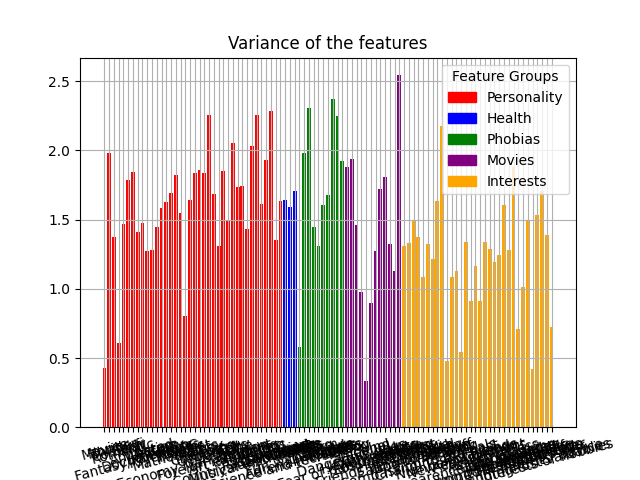

 the feature variance for the standardized data is: 1.0
 the feature variance for the minmax scaled data is: 0.1168053140204362


In [27]:
#compute the variance of each feature of the three datasets:
feat_var = X_df.var()
feat_var_std = Xstd_df.var()
feat_var_mm = Xmm_df.var()

#barplot of the variance of each feature in the original dadaset
plt.figure()
plt.bar(np.arange(len(X_df.columns)), feat_var, color = colors_for_plot)
plt.xticks(ticks=np.arange(len(X_df.columns)), 
           labels=X_df.columns,
           rotation=15)
legend_handles = [patches.Patch(color=color, label=group) for group, color in group_colors.items()]
plt.legend(handles=legend_handles, title="Feature Groups", loc="upper right")
plt.title('Variance of the features')
plt.grid()
plt.show()

print(f' the feature variance for the standardized data is: {feat_var_std}')
print(f' the feature variance for the minmax scaled data is: {feat_var_mm}')

Observations:
- Feature variance of non scaled data is distributed non homogeneously between the features: some of them have variance below 0.5 and some others above 2.
- Coherently with our rescaling of the data, the features of the standardized dataset have unitary variance, while features of the minmax scaled data all have the same variance, that is smaller than 1, in particular equal to 0.11

#### 2.3 compute all the n Principal Components (PCs) for each dataset _X_df_, _Xstd_df_, and _Xmm_df_. Then, visualize the curves of the cumulative explained variances and comment the results.

**NB (to delete)** :Principal components are new features created by PCA, which are linear combinations of the original features. 
 They are uncorrelated, and each principal component captures a direction of maximum variance in the data.

In [28]:
# perform pca and compute the explained variance of each PC for the three datasets
pca = PCA()
pca_std = PCA()
pca_mm = PCA()

pca.fit(X_df)
pca_std.fit(Xstd_df)
pca_mm.fit(Xmm_df)

# print the explained variance of each PC for the three datasets
print('####### The explained variance of each PC for non scaled data is:#######')
print(pca.explained_variance_)


print('####### The explained variance of each PC for standardized data is:#######')
print(pca_std.explained_variance_)


print('####### The explained variance of each PC for min max scaled data is:#######')
print(pca_mm.explained_variance_)

####### The explained variance of each PC for non scaled data is:#######
[12.1767059   9.34555564  6.50267687  5.14356884  4.64970742  3.89111119
  3.66360618  3.33597127  2.99938044  2.94582525  2.6283994   2.58507739
  2.5147865   2.38237423  2.36472364  2.20631128  2.08585222  2.02067479
  1.88354924  1.83202041  1.78130914  1.73525447  1.71478823  1.63029823
  1.59991066  1.55903696  1.55510528  1.52169313  1.46563941  1.40466862
  1.36734522  1.35964093  1.31424197  1.28585955  1.27031369  1.24759392
  1.20924643  1.17416022  1.14881124  1.13004624  1.10401994  1.08331002
  1.04520993  1.02318576  1.01198922  0.98420611  0.97845789  0.95676934
  0.93629811  0.90779882  0.88973932  0.86575447  0.85804353  0.82901369
  0.80969094  0.80358768  0.78664059  0.78253134  0.75807557  0.74317111
  0.71260229  0.70760553  0.69260943  0.67792073  0.65783806  0.64612705
  0.63058987  0.62304836  0.61160311  0.5833472   0.57013434  0.55774076
  0.5316669   0.52539881  0.51318434  0.51088182  0

Observations:
- In the three cases the first few principal components explain a larger variance, meaning that a good part of the dataset variability is concentrated along few directions (PCs); also, the explained variance declines as the number of PCs increases (being them oderdered wrt decreasing explained variance) and the last ones explain a little variance (so are not useful in characterizing the data and can be neglected when reducing dimensionality).
- In the standardized data (where each feature is tranformed in order to have 0 mean and 1 variance), the explained variance values are more evenly distributed compared to the non-scaled data: the first few components still explain most of the variance, but have lower values and this is because of the fact that after scaling, all features contribute equally; This tells us that in the original (non-scaled) data, certain features had much higher variance and dominated the first principal components (possibly because of the higher range of values they assumed). Also the variance values decline more gradually as we move through the components in the case of standardized data.
- Similar considerations hold also for min max scaled data (where data is rescaled to fit inside a (0,1) range interval), as the first few components have lower values wrt non scaled data; this is because the feature values are now confined in a smaller range, ensuring less contribution of large valued features to the explained variance of the principal compnents. We can also notice that the explained variance is now more uniformly distributed among the features wrt non scaled data.

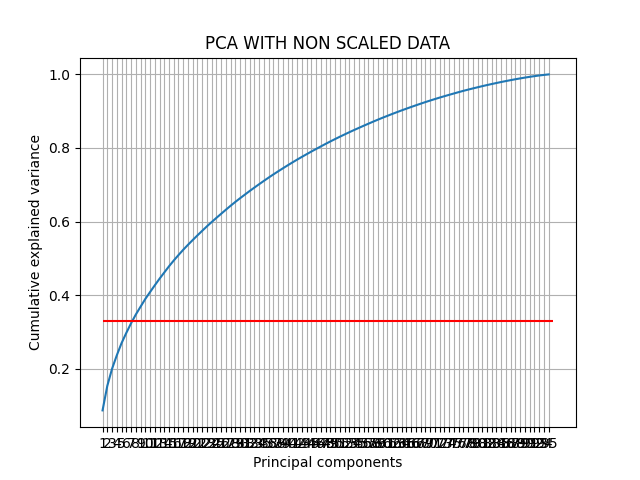

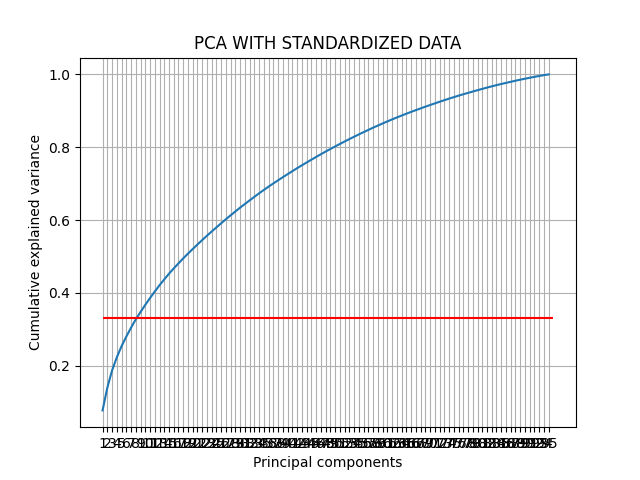

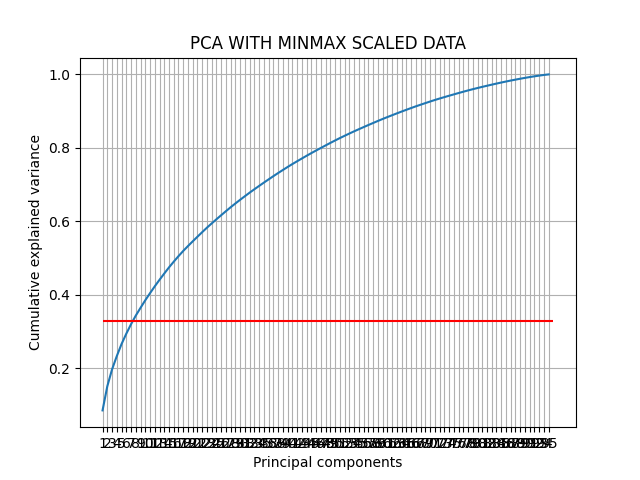

In [29]:
#plot of the curves of the cumulative explained variance of non scaled data
plt.figure()
plt.plot(np.cumsum(pca.explained_variance_ratio_))
plt.title('PCA WITH NON SCALED DATA')
plt.hlines(y=0.33, xmin=0, xmax=95, colors = 'r', label = '33% of cumulative explined variance')
plt.xticks(ticks=np.arange(pca.n_features_in_), 
           labels=[f'{i + 1}' for i in range(pca.n_features_in_)])
plt.xlabel('Principal components')
plt.ylabel('Cumulative explained variance')
plt.grid()
plt.show()

#plot of the curves of the cumulative explained variance of standardized data
plt.figure()
plt.plot(np.cumsum(pca_std.explained_variance_ratio_))
plt.title('PCA WITH STANDARDIZED DATA')
plt.hlines(y=0.33, xmin=0, xmax=95, colors = 'r', label = '33% of cumulative explined variance')
plt.xticks(ticks=np.arange(pca_std.n_features_in_), 
           labels=[f'{i + 1}' for i in range(pca_std.n_features_in_)])
plt.xlabel('Principal components')
plt.ylabel('Cumulative explained variance')
plt.grid()
plt.show()

#plot of the curves of the cumulative explained variance of minmax scaled data
plt.figure()
plt.plot(np.cumsum(pca_mm.explained_variance_ratio_))
plt.title('PCA WITH MINMAX SCALED DATA')
plt.hlines(y=0.33, xmin=0, xmax=95, colors = 'r', label = '33% of cumulative explined variance')
plt.xticks(ticks=np.arange(pca_mm.n_features_in_), 
           labels=[f'{i + 1}' for i in range(pca_mm.n_features_in_)])
plt.xlabel('Principal components')
plt.ylabel('Cumulative explained variance')
plt.grid()
plt.show()

Observations:
- There is no significant difference in the three graphs representing the comulative explained variance of the principal components, which is telling us that the dataset did not strictly require the scaling to have a better representation through principal components. This result is coherent with the fact that the range of values of the features is similar for all of them, so no feature significantly dominates the others because it assumes higher values.

- In the three cases, a very large number of PCs would be necessary to keep most of the dataset information; for example, to explain 80% of the variance, it would be necessary to use more than n/2 PCs, which gives us an intuition of the fact that reducing the dataset dimensionality to a few PCs will probably not give us a deep comprehension of the dataset.

- In the three graphs the red line represents the threshold limit for the cumulative explained variance that is required in the next exercise; it is possible to see that 33% of explained variance corresponds to a number of principal components strictly higher than 5 for all datasets, so in the following exercise we'll use m = min( m', 5) = 5 where m' st 33% of the total variance is explained.

## Exercise 3. Dimensionality Reduction and PC Interpretation

In the cells below, do the following operations:
1. For each one of the two dataframes _Xstd_df_, and _Xmm_df_, compute a new PCA for performing a dimensionality reduction with respect to $m$ dimensions. The value of $m$ must be $$m = \min\{m', 5\}\,,$$ where $m'$ is the value required for obtaining $33\%$ of the total variance.
2. For both the cases, visualize all the PCs and give a name/interpretation to them. **Comment and motivate your interpretations**. If possible, **compare the differences among the results obtained** for _Xstd_df_ and _Xmm_df_.
3. Perform the score graph for both the cases (_std_ and _mm_). If $m>3$, plot the score graph with respect to the first 3 PCs. All the **plots must show the names of the PCs on the axes** for better understanding the results.
4. **Optional:** plot more score graphs, coloring the dots with respect to any label in the list _labels_ that you believe can be interesting. **Comment and analyze this optional plots**.

#### 3.1 For each one of the two dataframes _Xstd_df_, and _Xmm_df_, compute a new PCA for performing a dimensionality reduction with respect to $m$ dimensions. The value of $m$ must be $$m = \min\{m', 5\}\,,$$ where $m'$ is the value required for obtaining $33\%$ of the total variance.

In [30]:
#Compute for both standardized data and mix max scaled data the value m
num_pcs = 0
pcs_needed = {'STD': 0, 'MM': 0}
for i in range(pca_std.n_features_in_):
    pcs_needed['STD'] += 1
    if (np.cumsum(pca_std.explained_variance_ratio_)[i]) >= 0.33 or pcs_needed['STD'] == 5:
        break
for i in range(pca_mm.n_features_in_):
    pcs_needed['MM'] += 1
    if (np.cumsum(pca_mm.explained_variance_ratio_)[i]) >= 0.33 or pcs_needed['MM']==5 :
        break
print('********************We need:*******************')
print('PCs with STD:', pcs_needed['STD'])
print('PCs with MM:', pcs_needed['MM'])

********************We need:*******************
PCs with STD: 5
PCs with MM: 5


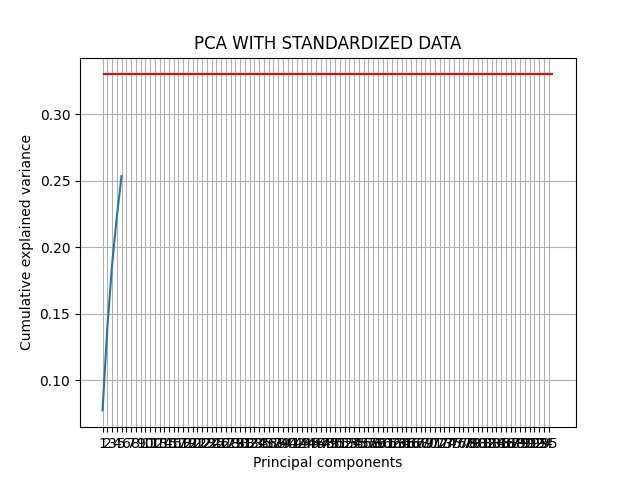

total explained variance with 5 Pcs for standardized data is 0.25344088515915986


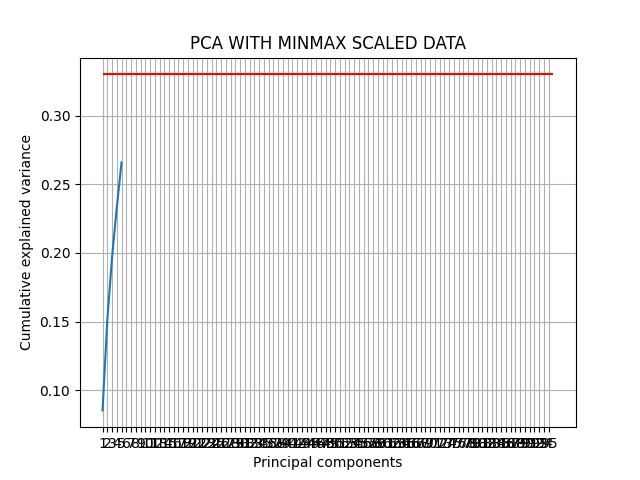

total explained variance with 5 Pcs for min max scaled data is 0.265890837690674


In [31]:
#perform pca on the two datasets using 5 principal components
m_std = pcs_needed['STD']
m_mm = pcs_needed['MM']
pcam_std = PCA(n_components = m_std)
pcam_mm = PCA(n_components = m_mm)

pcam_std.fit(Xstd_df)
pcam_mm.fit(Xmm_df)

#plot of the explained variance ratio for standardized data
plt.figure()
plt.plot(np.cumsum(pcam_std.explained_variance_ratio_))
plt.title('PCA WITH STANDARDIZED DATA')
plt.hlines(y=0.33, xmin=0, xmax=95, colors = 'r', label = '33% of cumulative explined variance')
plt.xticks(ticks=np.arange(pcam_std.n_features_in_), 
           labels=[f'{i + 1}' for i in range(pcam_std.n_features_in_)])
plt.xlabel('Principal components')
plt.ylabel('Cumulative explained variance')
plt.grid()
plt.show()
print(f'total explained variance with 5 Pcs for standardized data is {np.sum(pcam_std.explained_variance_ratio_)}')

#plot of the explained variance ratio for minmax scaled data
plt.figure()
plt.plot(np.cumsum(pcam_mm.explained_variance_ratio_))
plt.title('PCA WITH MINMAX SCALED DATA')
plt.hlines(y=0.33, xmin=0, xmax=95, colors = 'r', label = '33% of cumulative explined variance')
plt.xticks(ticks=np.arange(pcam_mm.n_features_in_), 
           labels=[f'{i + 1}' for i in range(pcam_mm.n_features_in_)])
plt.xlabel('Principal components')
plt.ylabel('Cumulative explained variance')
plt.grid()
plt.show()
print(f'total explained variance with 5 Pcs for min max scaled data is {np.sum(pcam_mm.explained_variance_ratio_)}')

It is possible to notice that using 5 principal components the total explained variance is very low:
- 25.34% for standardized data
- 26.59% for min max scaled data

#### 3.2 For both the cases, visualize all the PCs and give a name/interpretation to them. Comment and motivate your interpretations. If possible, compare the differences among the results obtained for _Xstd_df_ and _Xmm_df_.

##### Standardized data

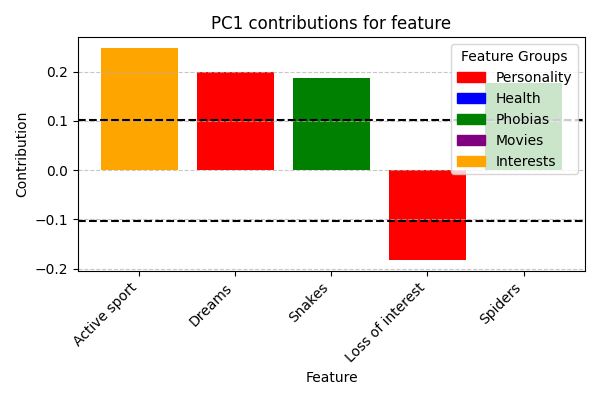


****************** PC1 **********************
the most contributing features are ['Active sport', 'Dreams', 'Snakes', 'Loss of interest', 'Spiders']

HIGH-VALUED POSITIVE COMPONENTS: ['Active sport', 'Dreams', 'Spiders', 'Snakes']

HIGH-VALUED NEGATIVE COMPONENTS: ['Loss of interest']
*********************************************



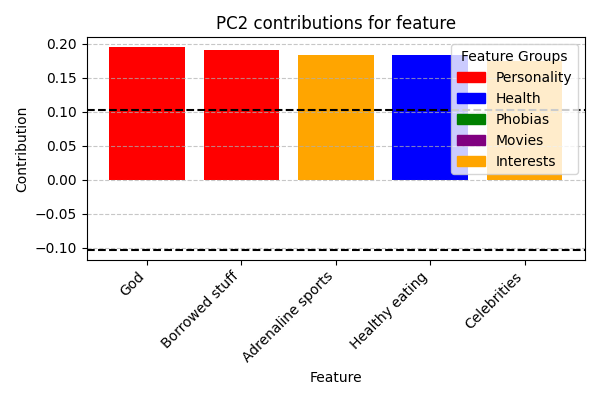


****************** PC2 **********************
the most contributing features are ['God', 'Borrowed stuff', 'Adrenaline sports', 'Healthy eating', 'Celebrities']

HIGH-VALUED POSITIVE COMPONENTS: ['Healthy eating', 'Celebrities', 'God', 'Adrenaline sports', 'Borrowed stuff']

HIGH-VALUED NEGATIVE COMPONENTS: []
*********************************************



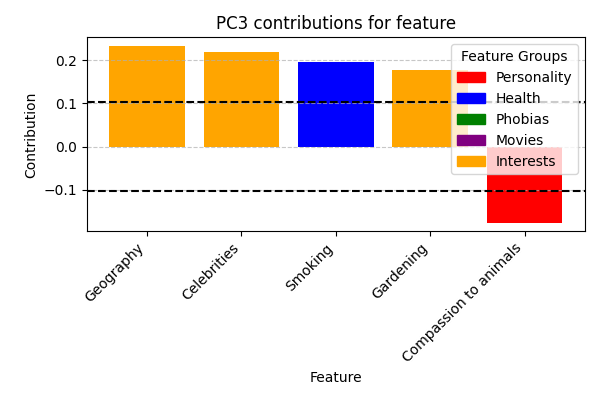


****************** PC3 **********************
the most contributing features are ['Geography', 'Celebrities', 'Smoking', 'Gardening', 'Compassion to animals']

HIGH-VALUED POSITIVE COMPONENTS: ['Celebrities', 'Geography', 'Smoking', 'Gardening']

HIGH-VALUED NEGATIVE COMPONENTS: ['Compassion to animals']
*********************************************



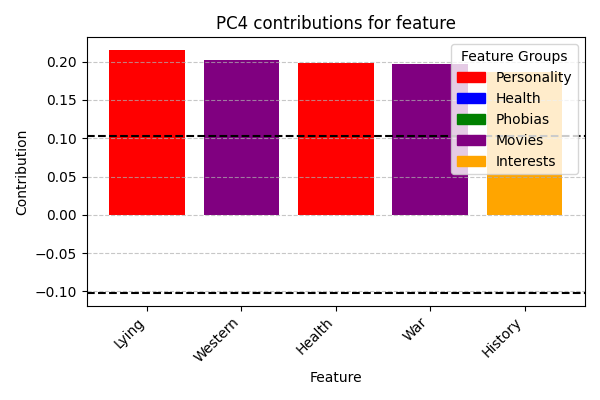


****************** PC4 **********************
the most contributing features are ['Lying', 'Western', 'Health', 'War', 'History']

HIGH-VALUED POSITIVE COMPONENTS: ['Health', 'Lying', 'War', 'Western', 'History']

HIGH-VALUED NEGATIVE COMPONENTS: []
*********************************************



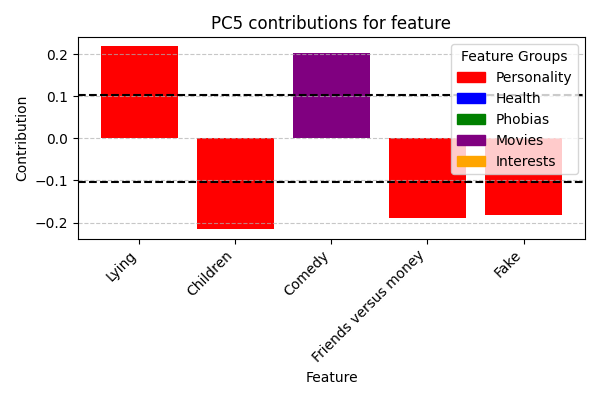


****************** PC5 **********************
the most contributing features are ['Lying', 'Children', 'Comedy', 'Friends versus money', 'Fake']

HIGH-VALUED POSITIVE COMPONENTS: ['Comedy', 'Lying']

HIGH-VALUED NEGATIVE COMPONENTS: ['Friends versus money', 'Children', 'Fake']
*********************************************



In [32]:
# Bar plot of the contribute to the explained variance of the five most relevant
# features to every principal component for standardized data
eps_std = np.sqrt(1 / pcam_std.n_features_in_)

for ii in range(m_std):
    # Compute squared loadings (contributions) for the current PC
    pc_loadings = pcam_std.components_[ii, :]  # Loadings for PC ii
    feature_contributions = pc_loadings**2     # Squared loadings (contributions)
    top_5_indices = np.argsort(feature_contributions)[::-1][:5]
    top_5_contributions = pc_loadings[top_5_indices]
    top_5_features = [these_features[i] for i in top_5_indices]
    plt.figure(figsize=(6, 4))
    now_colors = list(colors_for_plot[i] for i in top_5_indices)
    plt.bar(np.arange(5), top_5_contributions, color = now_colors)
    plt.axhline(y=eps_std, color='black', linestyle='--', label=f'Threshold (+/- {eps_std:.2f})')
    plt.axhline(y=-eps_std, color='black', linestyle='--')
    plt.title(f'PC{ii+1} contributions for feature')
    plt.ylabel('Contribution')
    plt.xlabel('Feature')
    plt.xticks(ticks=np.arange(5),
            labels=top_5_features,
            rotation=45, ha='right')
    #plt.xticks(ticks=np.arange(5), labels=top_5_features, rotation=45, ha='right')
    plt.tight_layout()
    plt.legend(handles=legend_handles, title="Feature Groups", loc="upper right")
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.show()

    std_pos_PCii = np.argwhere(pcam_std.components_[ii, :] >= eps_std).flatten()
    std_neg_PCii = np.argwhere(pcam_std.components_[ii, :] <= -eps_std).flatten()
    
    std_pos_features_PCii = [these_features[i] for i in (set(std_pos_PCii) & set(top_5_indices))]
    std_neg_features_PCii = [these_features[i] for i in (set(std_neg_PCii) & set(top_5_indices))]
    
    print('')
    print(f'****************** PC{ii+1} **********************')
    print(f"the most contributing features are {top_5_features}")
    print('')
    print(f'HIGH-VALUED POSITIVE COMPONENTS: {std_pos_features_PCii}')
    print('')
    print(f'HIGH-VALUED NEGATIVE COMPONENTS: {std_neg_features_PCii}')
    print('*********************************************')
    print('')

For each PC, the features with higher contribution are those for which larger values of that feature also show high values in the PC direction, and the features with lower contribution are those for which higher values for the feature imply low values in the PC direction.

The interpretation of the PCs could be the following:
- PC1: "Engagement vs. Detachment": Captures the contrast between high engagement (active sports, positive dreams +) and emotional disengagement (loss of interest -).
- PC2: "Values and Lifestyle Preferences": Reflects a combination of beliefs (God+), behaviors (healthy eating, borrowing responsibility+), and interests (adrenaline sports, celebrities +).
- PC3: "Interests and Ethical Balance": Highlights an interplay of knowledge (Geography+), societal focus (Celebrities+), personal habits (Smoking+), hobbies (Gardening+), and ethical priorities (Compassion to Animals−);
- PC4: "Entertainment Choices and Moral Awareness": Represents preferences for entertainment (Western and War movies), historical interests, moral behavior (Lying), and health consciousness
- PC5: "Integrity and Social Dynamics" : Captures the interplay between personal integrity (Lying +) and interpersonal dynamics, such as relationships and external values (Children, Friends versus money -).

In [33]:
# LIST OF THE NAMES ASSIGNED TO THE THREE PCs
pc_names_std =  ['active sports,good dreams(+),loss of interest(-)',  
            'religious,healthy,adrenalinic sports,celebrities(+)',
            'geography,celebrity,smoking(+),compassion to animals(-)', 
            'war western movies,lier,healthy,history(+)',
            'lier,comedies(+),children,friendsvsmoney,fake(-)'  
           ]

##### Min Max scaled data

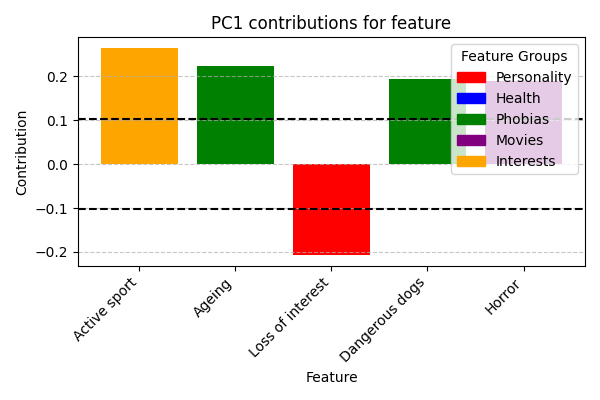


****************** PC1 **********************
the most contributing features are ['Active sport', 'Ageing', 'Loss of interest', 'Dangerous dogs', 'Horror']

HIGH-VALUED POSITIVE COMPONENTS: ['Ageing', 'Dangerous dogs', 'Horror', 'Active sport']

HIGH-VALUED NEGATIVE COMPONENTS: ['Loss of interest']
*********************************************



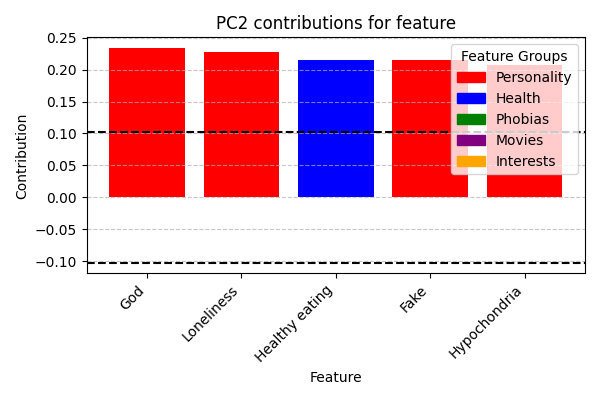


****************** PC2 **********************
the most contributing features are ['God', 'Loneliness', 'Healthy eating', 'Fake', 'Hypochondria']

HIGH-VALUED POSITIVE COMPONENTS: ['Healthy eating', 'Fake', 'Hypochondria', 'Loneliness', 'God']

HIGH-VALUED NEGATIVE COMPONENTS: []
*********************************************



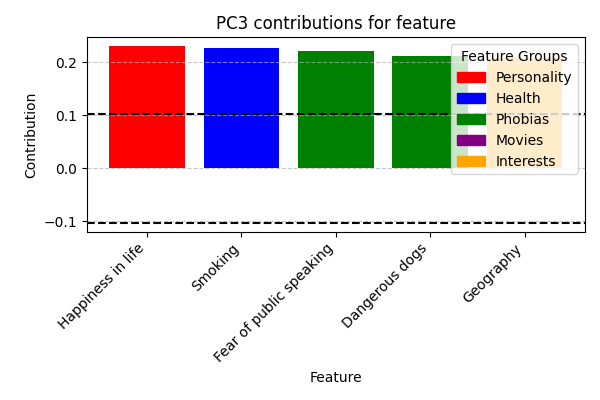


****************** PC3 **********************
the most contributing features are ['Happiness in life', 'Smoking', 'Fear of public speaking', 'Dangerous dogs', 'Geography']

HIGH-VALUED POSITIVE COMPONENTS: ['Happiness in life', 'Smoking', 'Geography', 'Dangerous dogs', 'Fear of public speaking']

HIGH-VALUED NEGATIVE COMPONENTS: []
*********************************************



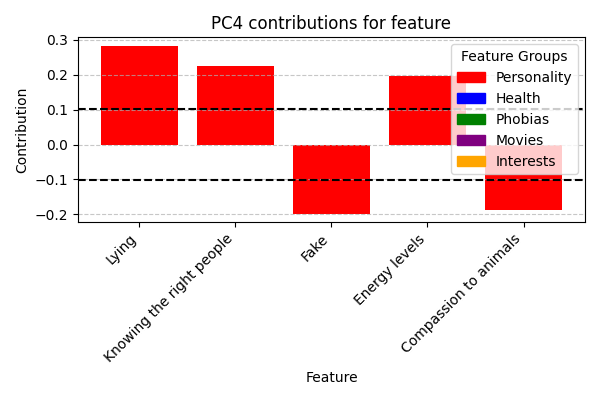


****************** PC4 **********************
the most contributing features are ['Lying', 'Knowing the right people', 'Fake', 'Energy levels', 'Compassion to animals']

HIGH-VALUED POSITIVE COMPONENTS: ['Knowing the right people', 'Energy levels', 'Lying']

HIGH-VALUED NEGATIVE COMPONENTS: ['Fake', 'Compassion to animals']
*********************************************



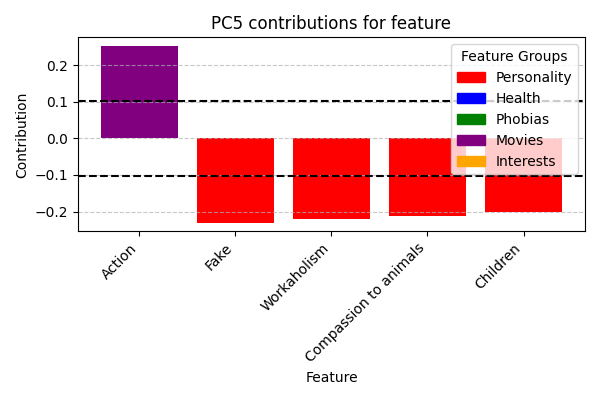


****************** PC5 **********************
the most contributing features are ['Action', 'Fake', 'Workaholism', 'Compassion to animals', 'Children']

HIGH-VALUED POSITIVE COMPONENTS: ['Action']

HIGH-VALUED NEGATIVE COMPONENTS: ['Children', 'Compassion to animals', 'Fake', 'Workaholism']
*********************************************



In [34]:
# Bar plot of the contribute to the explained variance of the five most relevant
# features to every principal component for min max scaled data
eps_mm = np.sqrt(1 / pcam_mm.n_features_in_)

for ii in range(m_mm):
    # Compute squared loadings (contributions) for the current PC
    pc_loadings = pcam_mm.components_[ii, :]  # Loadings for PC ii
    feature_contributions = pc_loadings**2     # Squared loadings (contributions)
    top_5_indices = np.argsort(feature_contributions)[::-1][:5]
    top_5_contributions = pc_loadings[top_5_indices]
    top_5_features = [these_features[i] for i in top_5_indices]
    plt.figure(figsize=(6, 4))
    now_colors = list(colors_for_plot[i] for i in top_5_indices)
    plt.bar(np.arange(5), top_5_contributions, color = now_colors)
    plt.axhline(y=eps_std, color='black', linestyle='--', label=f'Threshold (+/- {eps_std:.2f})')
    plt.axhline(y=-eps_std, color='black', linestyle='--')
    plt.title(f'PC{ii+1} contributions for feature')
    plt.ylabel('Contribution')
    plt.xlabel('Feature')
    plt.xticks(ticks=np.arange(5),
            labels=top_5_features,
            rotation=45, ha='right')
    #plt.xticks(ticks=np.arange(5), labels=top_5_features, rotation=45, ha='right')
    plt.tight_layout()
    plt.legend(handles=legend_handles, title="Feature Groups", loc="upper right")
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.show()

    mm_pos_PCii = np.argwhere(pcam_mm.components_[ii, :] >= eps_std).flatten()
    mm_neg_PCii = np.argwhere(pcam_mm.components_[ii, :] <= -eps_std).flatten()
    
    mm_pos_features_PCii = [these_features[i] for i in (set(mm_pos_PCii) & set(top_5_indices))]
    mm_neg_features_PCii = [these_features[i] for i in (set(mm_neg_PCii) & set(top_5_indices))]
    
    print('')
    print(f'****************** PC{ii+1} **********************')
    print(f"the most contributing features are {top_5_features}")
    print('')
    print(f'HIGH-VALUED POSITIVE COMPONENTS: {mm_pos_features_PCii}')
    print('')
    print(f'HIGH-VALUED NEGATIVE COMPONENTS: {mm_neg_features_PCii}')
    print('*********************************************')
    print('')

The interpretation of the PCs could be the following:
- PC1: "Resilience vs. Apathy" : Represents the contrast between resilience and engagement with life’s challenges (Ageing, Active sport, Dangerous dogs +) and emotional apathy (Loss of interest -).
- PC2: "Faith and Vulnerability": Highlights the focus on spiritual beliefs and emotional sensitivity (God, Loneliness, Hypochondria +) combined with health-conscious behavior (Healthy eating, Fake +).
- PC3: "Fulfillment and Challenges": Represents the pursuit of happiness and intellectual fulfillment (Happiness in life, Geography +) balanced against dealing with fears and risky habits (Smoking, Dangerous dogs, Fear of public speaking +)
- PC4: "Strategic Relationships vs. Sincerity": Reflects the contrast between leveraging social connections and energy (Knowing the right people, Energy levels, Lying +) and valuing honesty and compassion (Fake, Compassion to animals -).
- PC5: "Energy vs. Serenity": Represents the contrast between action-oriented, high-energy preferences (Action +) and a calmer, more compassionate approach to life (Compassion to animals, Children, Fake -).

In [35]:
# LIST OF THE NAMES ASSIGNED TO THE THREE PCs
pc_names_mm =  ['fear ageing and dangerous dogs,active sports,horror movies(+),loss of interest(-)',  
            'religious,healthy,lonely,fake,hypocondriac(+)',
            'seeks happiness,smoker,scared of public speaking and dangerous dogs,geography(+)', 
            'lier,energetic,connects with right people(+),fake,compassion to animals(-)',
            'action movies(+),fake,workaholic,compassion to anlimals,children(-)'  
           ]

#### 3.3 Perform the score graph for both the cases (_std_ and _mm_). If $m>3$, plot the score graph with respect to the first 3 PCs. All the plots must show the names of the PCs on the axes for better understanding the results.

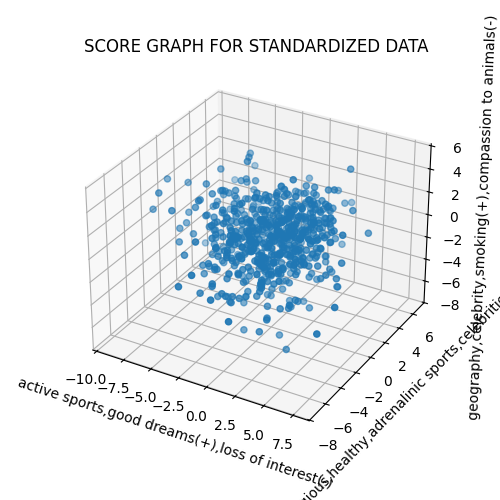

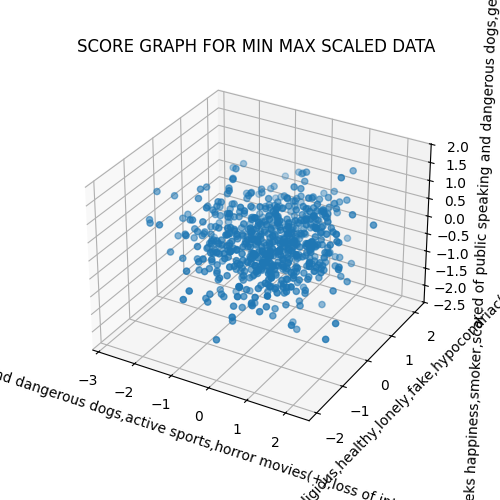

In [36]:
#score graphs for standardized data
Y_std = pcam_std.transform(Xstd_df)

sg_3d = plt.figure(figsize=(5, 5))
ax_sg_3d = sg_3d.add_subplot(111, projection='3d')
ax_sg_3d.scatter(Y_std[:,0], Y_std[:,1], Y_std[:,2])  # <-- TODO!!
plt.title('SCORE GRAPH FOR STANDARDIZED DATA')
ax_sg_3d.set_xlabel(pc_names_std[0])
ax_sg_3d.set_ylabel(pc_names_std[1])
ax_sg_3d.set_zlabel(pc_names_std[2])
plt.grid()
plt.show()

#score graphs for min max scaled data
Y_mm = pcam_mm.transform(Xmm_df)

sg_3d = plt.figure(figsize=(5,5))
ax_sg_3d = sg_3d.add_subplot(111, projection='3d')
ax_sg_3d.scatter(Y_mm[:,0], Y_mm[:,1], Y_mm[:,2])  # <-- TODO!!
plt.title('SCORE GRAPH FOR MIN MAX SCALED DATA')
ax_sg_3d.set_xlabel(pc_names_mm[0])
ax_sg_3d.set_ylabel(pc_names_mm[1])
ax_sg_3d.set_zlabel(pc_names_mm[2])
plt.grid()
plt.show()

### Score Graphs wrt some meaningful labels
#### 3.4 Optional: plot more score graphs, coloring the dots with respect to any label in the list _labels_ that you believe can be interesting.Comment and analyze this optional plots.

The evaluation of the results highlights that all labels except for Gender do not seem to be meaninfully explained by the first three PCs, so only 2 representative examples of non meaningful labels (a binary label and a non binary one) are commented. The selected commented labels for the 2 datasets are: Gender, Age, Home Town Type.

##### standardized data

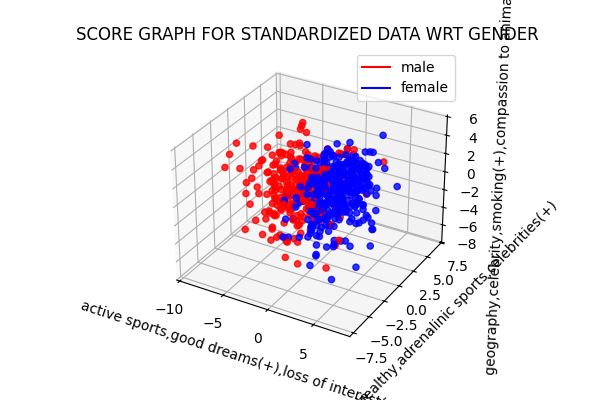

In [37]:
# GENDER
# Associating a color to every gender
gender_colors = {'male':'red',
                'female':'blue'}
# adding a color column to the non encoded dataframe to map labels
X_df_nonenc['Gender Color'] = X_df_nonenc['Gender'].map(gender_colors)
# Making a custom legend for the colors
gender_colors_legend = [Line2D([0], [0], color=gender_colors[k]) for k in gender_colors.keys()]

#scatter plot
sg2_3d = plt.figure(figsize=(6,4))
ax_sg2_3d = sg2_3d.add_subplot(111, projection='3d')
ax_sg2_3d.scatter(Y_std[:,0], Y_std[:,1], Y_std[:,2], c=X_df_nonenc['Gender Color'].values, alpha=0.8) 
plt.title('SCORE GRAPH FOR STANDARDIZED DATA WRT GENDER')
ax_sg2_3d.set_xlabel(pc_names_std[0])
ax_sg2_3d.set_ylabel(pc_names_std[1])
ax_sg2_3d.set_zlabel(pc_names_std[2])
plt.legend(gender_colors_legend, [k for k in gender_colors.keys()])
plt.grid()
plt.show()

The Gender label is the only one for which it is possible to see a separation in the dataset in the 3D space; despite that, the male (red) and female (blue) data points show partial overlap. This suggests that the first three principal components capture differences in the data that are in some way correlated with gender. 

For example, males tend to have negative values of PC1, resulting in lower values of the features 'Active sport', 'Dreams',  'Spiders', 'Snakes' and higher values in the answer 'Loss of interest'. This could be interpreted as: males are not very afraid of spiders and snakes, do not make good dreams and do not like active sports and lose interest easily. On the contrary, females have positive values of PC1, which can be interpreted as the opposite (are afraid of snakes and spiders, do not lose interest easily, ecc).

The interpretations are not to be taken too seriously, since the clustering is not perfectly distinct, which implies that while the features used to calculate the principal components do contain gender-specific variance, it is not completely discriminatory.

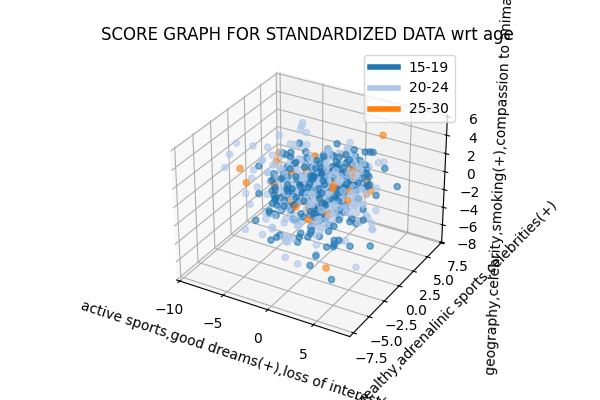

In [38]:
# AGE
colors = cm.tab20.colors[:20]
age = np.sort(X_df_nonenc['Age'].unique())
# Two ways:
# 1) Associating a color to every age
#age_colors = {age[i]:colors[0] for i in range(len(age))}
# or:
# 2) Define age ranges and corresponding colors
age_ranges = {
    (15, 19): colors[0],  # Color for ages 15 to 19
    (20, 25): colors[1],  # Color for ages 20 to 25
    (26, 30): colors[2],  # Color for ages 26 to 30
}
# Function to assign a color based on the age range
def assign_color(age):
    for age_range, color in age_ranges.items():
        if age_range[0] <= age <= age_range[1]:
            return color
    return colors[-1]
    
# Assign colors to the DataFrame
# 1)
#X_df_nonenc['Age Color'] = X_df_nonenc['Age'].map(age_colors)
# or:
# 2)
X_df_nonenc['Age Color'] = X_df_nonenc['Age'].apply(assign_color)

# Create a custom legend for the age ranges and colors
# 1)
#age_colors_legend = [Line2D([0], [0], color=age_colors[k]) for k in age_colors.keys()]
#or:
# 2)
age_colors_legend = [Line2D([0], [0], color=color, lw=4, label=f'{age_range[0]}-{age_range[1]}') 
                     for age_range, color in age_ranges.items()]

#scatter plot
sg2_3d = plt.figure(figsize=(6,4))
ax_sg2_3d = sg2_3d.add_subplot(111, projection='3d')
ax_sg2_3d.scatter(Y_std[:,0], Y_std[:,1], Y_std[:,2],c=X_df_nonenc['Age Color'].values, alpha=0.6) 
plt.title('SCORE GRAPH FOR STANDARDIZED DATA wrt age')
ax_sg2_3d.set_xlabel(pc_names_std[0])
ax_sg2_3d.set_ylabel(pc_names_std[1])
ax_sg2_3d.set_zlabel(pc_names_std[2])
# 1)
#plt.legend(age_colors_legend, [k for k in age_colors.keys()])
#or:
# 2)
plt.legend(age_colors_legend, ['15-19', '20-24', '25-30'])
plt.grid()
plt.show()

The points for the different age groups are highly overlapping in 3D space. This suggests that the variance captured by the first three principal components does not provide clear separation among the age groups, meaning that individuals from different age groups share similarities in the features contributing to these PCs.

C:\Users\lucia\AppData\Local\Temp\ipykernel_15912\904201897.py:11: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  sg_3d = plt.figure(figsize=(6,4))


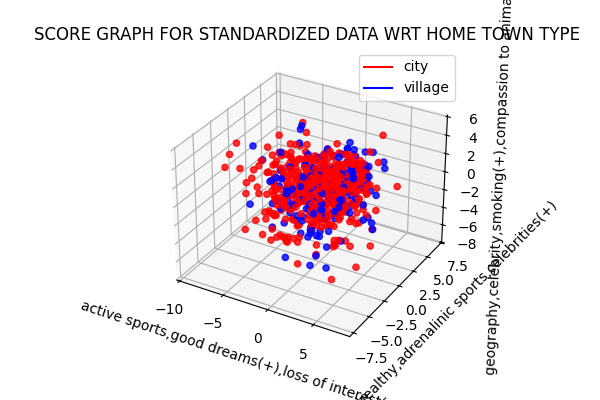

In [39]:
#score graphs wrt meaningful labels
# Associating a color to every number of kids at home
hometowntypes_colors = {'city':'red',
                        'village':'blue'}
# adding a color column to the non encoded dataframe to map labels
X_df_nonenc['Home Town Type Color'] = X_df_nonenc['Home Town Type'].map(hometowntypes_colors)

# Making a custom legend for the colors
hometowntypes_colors_legend = [Line2D([0], [0], color=hometowntypes_colors[k]) for k in hometowntypes_colors.keys()]
# scatter plot
sg_3d = plt.figure(figsize=(6,4))
ax_sg_3d = sg_3d.add_subplot(111, projection='3d')
ax_sg_3d.scatter(Y_std[:,0], Y_std[:,1], Y_std[:,2],c=X_df_nonenc['Home Town Type Color'].values, alpha=0.8)  
plt.title('SCORE GRAPH FOR STANDARDIZED DATA WRT HOME TOWN TYPE')
ax_sg_3d.set_xlabel(pc_names_std[0])
ax_sg_3d.set_ylabel(pc_names_std[1])
ax_sg_3d.set_zlabel(pc_names_std[2])
plt.legend(hometowntypes_colors_legend, [k for k in hometowntypes_colors.keys()])
plt.grid()
plt.show()

The home town type score graph leads us to doing the same considerations as for age: points in the 3D space are all mixed together and no significant division wrt home town type can be seen in the data considering the first three PCs.

The score graphs for Age and Home Town Type are two significant examples (a non binary and a binary label) of the fact that dimensionality reduction to 3 PCs does not lead to a meaningful interpretation of the dataset. The same results (not reported for conciseness) are obtained also for the other labels. Additional principal components (beyond the first three) or alternative features might be needed to reveal more specific patterns.

##### for min max scaled data

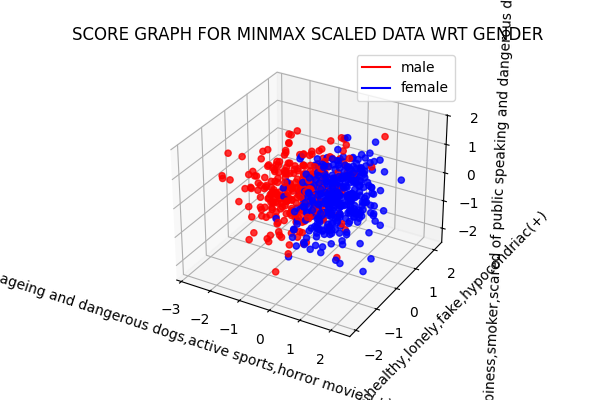

In [40]:
# GENDER
# scatter plot
sg2_3d = plt.figure(figsize=(6,4))
ax_sg2_3d = sg2_3d.add_subplot(111, projection='3d')
ax_sg2_3d.scatter(Y_mm[:,0], Y_mm[:,1], Y_mm[:,2], c=X_df_nonenc['Gender Color'].values, alpha=0.8) 
plt.title('SCORE GRAPH FOR MINMAX SCALED DATA WRT GENDER')
ax_sg2_3d.set_xlabel(pc_names_mm[0])
ax_sg2_3d.set_ylabel(pc_names_mm[1])
ax_sg2_3d.set_zlabel(pc_names_mm[2])
plt.legend(gender_colors_legend, [k for k in gender_colors.keys()])
plt.grid()
plt.show()

As for the case of standardized data, the only label for which the first 3 PCs show some pattern in the datat is Gender. In the min max scaled case, male and females are again mainly differenciated for the values of the 1st PC: the first have negative values of PC1 and the latter positive values of PC1. A possible interpretation based on the most contributing features could be the following: males are not afraid of dogs and of ageing, do not like active sports and lose interest easily. The contrary could be stated for females.

It is interesting to notice that the main gender-discriminant cathegory of features is Phobias, of snakes and spiders for std data and of dogs and ageing for mm data. Moreover, the two datasets share some relevant features distinguishing among males and females, in particular, action sports, losing interest. 

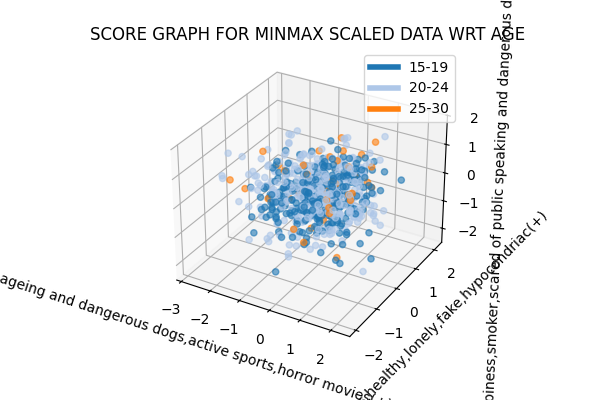

In [41]:
# AGE
#scatter plot
sg2_3d = plt.figure(figsize=(6,4))
ax_sg2_3d = sg2_3d.add_subplot(111, projection='3d')
ax_sg2_3d.scatter(Y_mm[:,0], Y_mm[:,1], Y_mm[:,2],c=X_df_nonenc['Age Color'].values, alpha=0.6) 
plt.title('SCORE GRAPH FOR MINMAX SCALED DATA WRT AGE')
ax_sg2_3d.set_xlabel(pc_names_mm[0])
ax_sg2_3d.set_ylabel(pc_names_mm[1])
ax_sg2_3d.set_zlabel(pc_names_mm[2])
# 1)
#plt.legend(age_colors_legend, [k for k in age_colors.keys()])
#or:
# 2)
plt.legend(age_colors_legend, ['15-19', '20-24', '25-30'])
plt.grid()
plt.show()

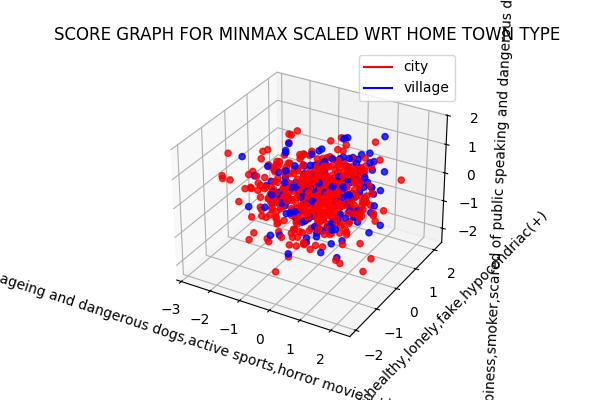

In [42]:
# HOME TOWN TYPE
# scatter plot
sg_3d = plt.figure(figsize=(6,4))
ax_sg_3d = sg_3d.add_subplot(111, projection='3d')
ax_sg_3d.scatter(Y_mm[:,0], Y_mm[:,1], Y_mm[:,2],c=X_df_nonenc['Home Town Type Color'].values, alpha=0.8)  
plt.title('SCORE GRAPH FOR MINMAX SCALED WRT HOME TOWN TYPE')
ax_sg_3d.set_xlabel(pc_names_mm[0])
ax_sg_3d.set_ylabel(pc_names_mm[1])
ax_sg_3d.set_zlabel(pc_names_mm[2])
plt.legend(hometowntypes_colors_legend, [k for k in hometowntypes_colors.keys()])
plt.grid()
plt.show()

Again, the same considerations as for std data are valid for min max scaled data. The first three PCs are only able to slightly separate data by gender, while for the other labels the separation or evidence of meaningful patterns is absent.

## Exercise 4. $k$-Means

In the cells below, do the following operations:
1. For each one of the two datasets (_std_ and _mm_), run the $k$-Means for clustering the data. In particular, **use the silohuette score for identify the best value for $k\in\{3, \ldots, 10\}$**.
2. Plot the score graphs of exercise 3.3, adding the centroids of the cluster.
3. Observing the centroids coordinates in the PC space, **give a name/interpretation to them**, exploiting the names you assigned to the PCs. **Comment and motivate your interpretations**.

#### 4.1 For each one of the two datasets (_std_ and _mm_), run the $k$-Means for clustering the data. In particular, use the silohuette score for identify the best value for $k\in\{3, \ldots, 10\}$.

In [43]:
# INITIALIZE SOME LISTS TO STORE THE TEMPORARY RESULTS AND, THEN, MAKE COMPARISONS
km_list_std = []
km_list_mm = []
silcoeff_list_std = []
silcoeff_list_mm = []
k_list = list(range(3, 11))

# START THE FOR-CYCLE TO RUN THE k-MEANS AND MEASURING THE SILHOUETTE COEFFICIENT
for i in range(len(k_list)):
    print(f'****************** Computing k-MEANS with k={k_list[i]} ******************')
    km_list_std.append(KMeans(n_clusters=k_list[i], random_state=random_seed))
    km_list_mm.append(KMeans(n_clusters=k_list[i], random_state=random_seed))
    km_std = km_list_std[i]
    km_mm = km_list_mm[i]
    km_std.fit(Y_std) 
    km_mm.fit(Y_mm) 
    silcoeff_list_std.append(silhouette_score(Y_std, km_std.fit_predict(Y_std)))
    silcoeff_list_mm.append(silhouette_score(Y_mm, km_mm.fit_predict(Y_mm)))  
    print('')

# FIND THE BEST VALUE OF k AND THE BEST KMeans OBJECT
i_best_std = np.argmax(silcoeff_list_std) 
i_best_mm = np.argmax(silcoeff_list_mm) 
k_std = k_list[i_best_std]
k_mm = k_list[i_best_mm]
km_std = km_list_std[i_best_std]
km_mm = km_list_mm[i_best_mm]

# VISUALIZE THE RESULT
print('')
print('')
print('****************** RESULTS OF THE SEARCH... ******************')
print(f'BEST SILHOUETTE SCORE FOR STANDARDIZED DATA: {np.max(silcoeff_list_std)} --> k = {k_std}')
print(f'BEST SILHOUETTE SCORE FOR MIN MAX SCALED DATA: {np.max(silcoeff_list_mm)} --> k = {k_mm}')
print('**************************************************************')

****************** Computing k-MEANS with k=3 ******************

****************** Computing k-MEANS with k=4 ******************

****************** Computing k-MEANS with k=5 ******************

****************** Computing k-MEANS with k=6 ******************

****************** Computing k-MEANS with k=7 ******************

****************** Computing k-MEANS with k=8 ******************

****************** Computing k-MEANS with k=9 ******************

****************** Computing k-MEANS with k=10 ******************



****************** RESULTS OF THE SEARCH... ******************
BEST SILHOUETTE SCORE FOR STANDARDIZED DATA: 0.16657285752752107 --> k = 3
BEST SILHOUETTE SCORE FOR MIN MAX SCALED DATA: 0.18675439221728957 --> k = 3
**************************************************************


Let us also plot the silhouette scores for different values of k to see how they change as k increase

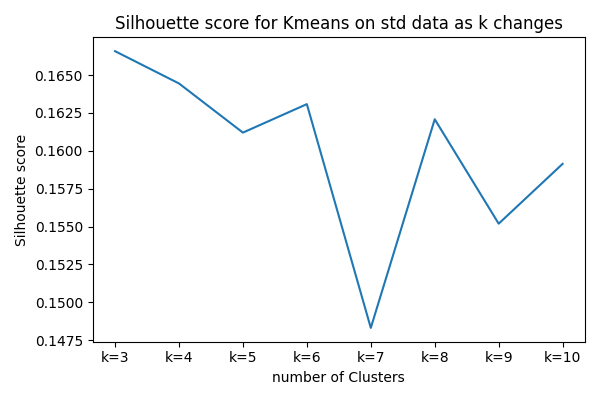

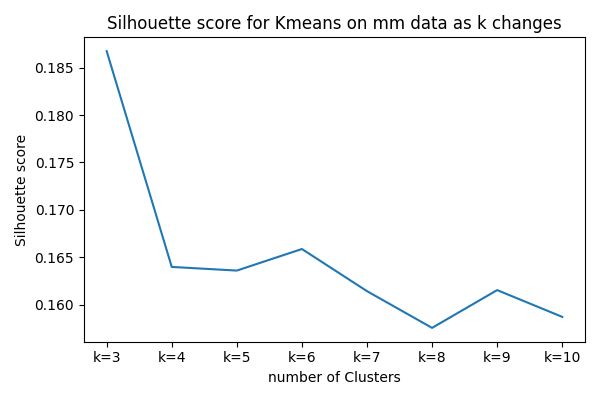

In [44]:
#bar plots of silhouette scores
plt.figure(figsize=(6, 4))
plt.plot(np.arange(len(k_list)), silcoeff_list_std)
plt.title('Silhouette score for Kmeans on std data as k changes')
plt.ylabel('Silhouette score')
plt.xlabel('number of Clusters')
plt.xticks(ticks=np.arange(len(k_list)),
        labels= [f'k={i}' for i in k_list])
plt.tight_layout()
plt.show()

#bar plots of silhouette scores
plt.figure(figsize=(6, 4))
plt.plot(np.arange(len(k_list)), silcoeff_list_mm)
plt.title('Silhouette score for Kmeans on mm data as k changes')
plt.ylabel('Silhouette score')
plt.xlabel('number of Clusters')
plt.xticks(ticks=np.arange(len(k_list)),
        labels= [f'k={i}' for i in k_list])
plt.tight_layout()
plt.show()

#### 4.2 Plot the score graphs of exercise 3.3, adding the centroids of the cluster.

##### standardized data

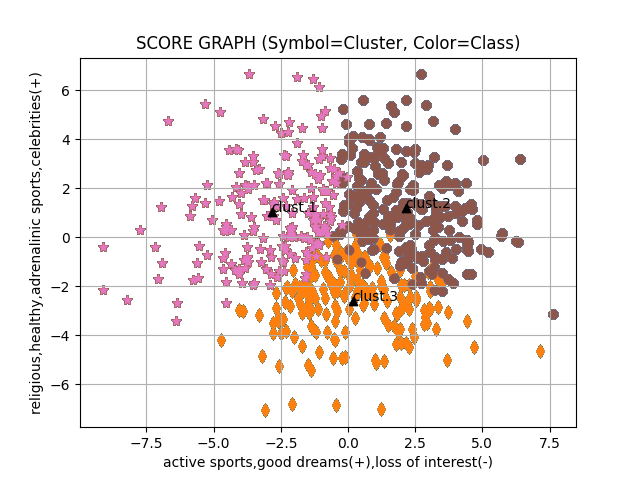

C:\Users\lucia\OneDrive\Desktop\Università\II_ANNO\Computational\laboratori\virtualenv\Lib\site-packages\matplotlib\collections.py:996: RuntimeWarning: invalid value encountered in sqrt
  scale = np.sqrt(self._sizes) * dpi / 72.0 * self._factor


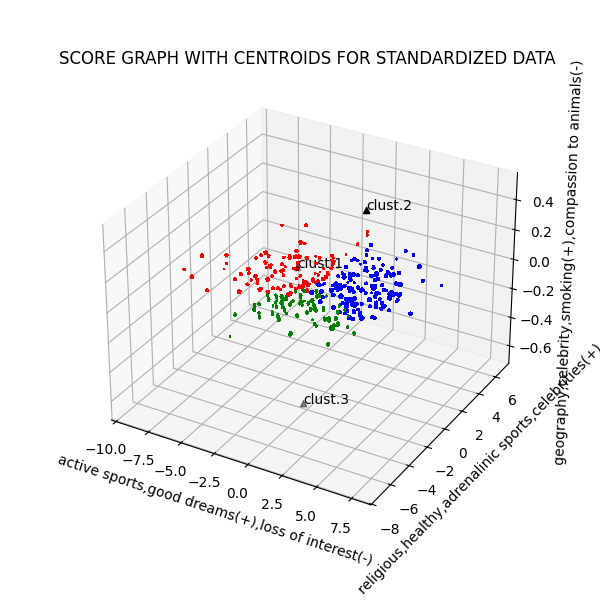

In [45]:
# score graph with centroids for standardized data
# defining markers and colors for each cluster
markers_dict = {0: '*', 1: 'o', 2: 'd'}
colors = ['red', 'blue', 'green']
# 2d scatter plot
plt.figure()
for ll in km_std.labels_:
    plt.scatter(Y_std[km_std.labels_ == ll, 0], Y_std[km_std.labels_ == ll, 1], marker=markers_dict[ll])
plt.scatter(km_std.cluster_centers_[:, 0], km_std.cluster_centers_[:, 1], c='black', marker='^')
plt.title('SCORE GRAPH (Symbol=Cluster, Color=Class)')
plt.xlabel(pc_names_std[0])
plt.ylabel(pc_names_std[1])
for kk in range(k_std):
 plt.text(km_std.cluster_centers_[kk,0], km_std.cluster_centers_[kk, 1], f'clust.{kk+1}')
plt.grid()
plt.show()

# scatter plot
sg_3d_km = plt.figure(figsize=(6,6))
ax_sg_3d_km = sg_3d_km.add_subplot(111, projection='3d')
for ll in km_std.labels_:
    plt.scatter(Y_std[km_std.labels_ == ll, 0], Y_std[km_std.labels_ == ll, 1],Y_std[km_std.labels_ == ll,2], c= colors[ll], marker=markers_dict[ll])
ax_sg_3d_km.scatter(km_std.cluster_centers_[:,0], km_std.cluster_centers_[:,1], km_std.cluster_centers_[:,2],c='black', marker='^')
# writing cluster indices in plot
for kk in range(k_std):
 ax_sg_3d_km.text(km_std.cluster_centers_[kk,0], km_std.cluster_centers_[kk, 1], km_std.cluster_centers_[kk, 2], f'clust.{kk+1}')
plt.title('SCORE GRAPH WITH CENTROIDS FOR STANDARDIZED DATA')
ax_sg_3d_km.set_xlabel(pc_names_std[0])
ax_sg_3d_km.set_ylabel(pc_names_std[1])
ax_sg_3d_km.set_zlabel(pc_names_std[2])
plt.grid()
plt.show()


The 3D score graph shows that along the direction given by the 3rd PC data is all distributed aroung the same value (data is almost distributed on a plane), which suggests that this clustering representation can be better visualized in a 2D plane and that PC3 does not contribute much to the clustering formation.

For better understanding, let us also make barplots showing the contribution of each PC to each centroid.

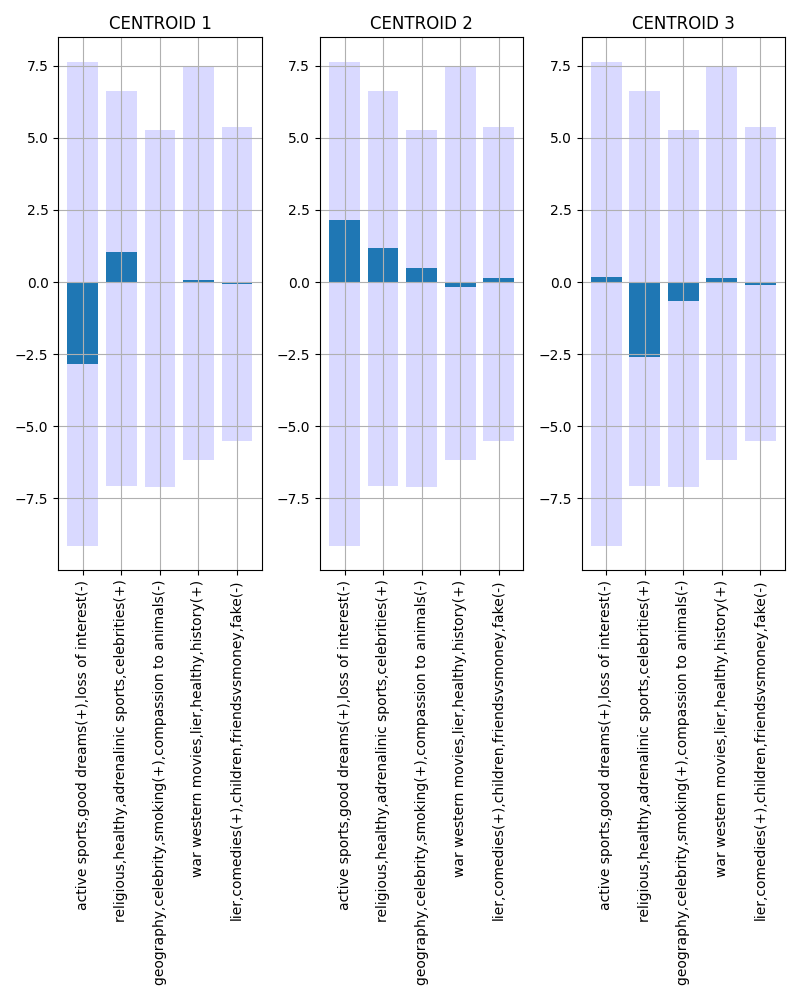

In [46]:
# standardized data
# COMPUTE THE MAX/MIN VALUES IN THE PC-SPACE
maxs_y = Y_std.max(axis=0)  
mins_y = Y_std.min(axis=0) 

# MAKE THE BARPLOTS OF THE CENTROIDS 
fig_centroids, ax_centroids = plt.subplots(1, 3, figsize=(8, 10))
for ii in range(k_std):
    ax_centroids[ii].bar(np.arange(km_std.cluster_centers_.shape[1]), maxs_y, color='blue', alpha=0.15)
    ax_centroids[ii].bar(np.arange(km_std.cluster_centers_.shape[1]), mins_y, color='blue', alpha=0.15)
    ax_centroids[ii].bar(np.arange(km_std.cluster_centers_.shape[1]), km_std.cluster_centers_[ii, :])
    ax_centroids[ii].set_xticks(ticks=np.arange(km_std.cluster_centers_.shape[1]))
    ax_centroids[ii].set_xticklabels(labels=pc_names_std, rotation=90)
    ax_centroids[ii].grid(visible=True, which='both')
    plt.tight_layout()
    ax_centroids[ii].set_title(f'CENTROID {ii+1}')
    #plt.tight_layout()

As previously forseen, the 3rd PC has a very low relevance in the clustering formation. We can also see that PC4 and PC5 do not contribute at all.

#### 4.3 Observing the centroids coordinates in the PC space, give a name/interpretation to them, exploiting the names you assigned to the PCs. Comment and motivate your interpretations.

We can observe that:
- Centroid 1 is characterized by negative values of PC1 and positive values of PC2

- Centroid 2 is characterized by positive values of PC1, PC2 and PC3 (very small contribution)

- Centroid 3 is characterized by negative values of PC2 and PC3 (very small contribution)

We see that Centroid 1 shows opposite characteristics wrt Centroid 2.

As we expected from the scatterplots of the PCs, the data is all distributed in one "central cloud" around the origin in the 2D space of the first two PCs, and does not create well separated groups of points; The consequence is that, as we expected from the PCA results, the first three PCs are not able to show the presence of patterns in the data.

Centroids interpretation:
- Centroid 1 is characterized by the opposite of PC1 : active sports, good dreams, afraid of snakes and spiders(-) are negatively contributing feature, loss of interest(+) is a positively contributing feature.
- Centroid 2 is characterized by the values of PC1 : active sports, good dreams, afraid of snakes and spiders(+) are positively contributing fetures, loss of interest(-) is a negatively contributing feature.
- Centroid 3 is characterized by the opposite of PC2 : religious, healthy, adrenalinic sports, celebrities(-) are the most negatively contributing features.

In [47]:
# LIST OF THE NAMES ASSIGNED TO THE FOUR CLUSTERS
cluster_names_std =  ['active sports, good dreams, afraid of snakes and spiders(-), loss of interest(+)',
                  'active sports, God, borrowed stuff(+), loss of interest(-) ',
                  'religious, healthy, adrenalinic sports, celebrities (-)'
                 ]

#### min max scaled data

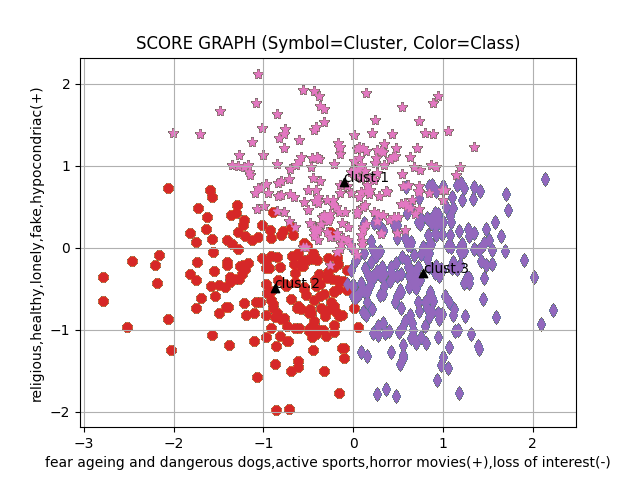

C:\Users\lucia\OneDrive\Desktop\Università\II_ANNO\Computational\laboratori\virtualenv\Lib\site-packages\matplotlib\collections.py:996: RuntimeWarning: invalid value encountered in sqrt
  scale = np.sqrt(self._sizes) * dpi / 72.0 * self._factor


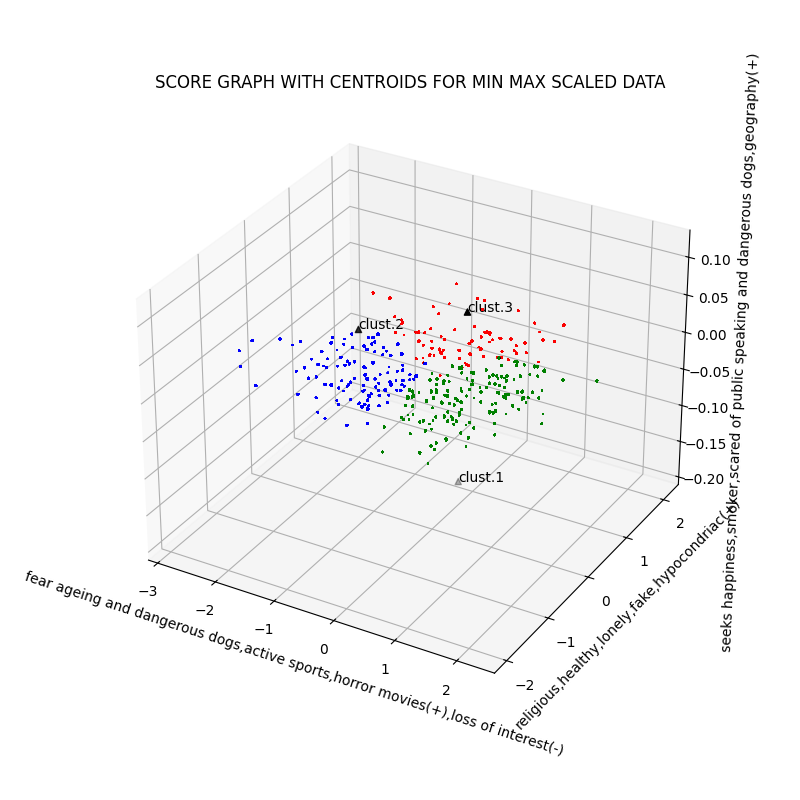

In [48]:
#score graph with centroids for min max scaled data
# 2d scatter plot
plt.figure()
for ll in km_mm.labels_:
    plt.scatter(Y_mm[km_mm.labels_ == ll, 0], Y_mm[km_mm.labels_ == ll, 1], marker=markers_dict[ll])
plt.scatter(km_mm.cluster_centers_[:, 0], km_mm.cluster_centers_[:, 1], c='black', marker='^')
plt.title('SCORE GRAPH (Symbol=Cluster, Color=Class)')
plt.xlabel(pc_names_mm[0])
plt.ylabel(pc_names_mm[1])
for kk in range(k_mm):
 plt.text(km_mm.cluster_centers_[kk,0], km_mm.cluster_centers_[kk, 1], f'clust.{kk+1}')
plt.grid()
plt.show()

#3d score graph
markers_dict = {0: '*', 1: 'o', 2: 'd'}
colors = ['red', 'blue', 'green']
sg_3d_km = plt.figure(figsize=(8, 8))
ax_sg_3d_km = sg_3d_km.add_subplot(111, projection='3d')
for ll in km_mm.labels_:
    plt.scatter(Y_mm[km_mm.labels_ == ll, 0], Y_mm[km_mm.labels_ == ll, 1],Y_mm[km_mm.labels_ == ll,2], c= colors[ll], marker=markers_dict[ll])
ax_sg_3d_km.scatter(km_mm.cluster_centers_[:,0], km_mm.cluster_centers_[:,1], km_mm.cluster_centers_[:,2],c='black', marker='^')
# writing cluster indices in plot
for kk in range(k_mm):
 ax_sg_3d_km.text(km_mm.cluster_centers_[kk,0], km_mm.cluster_centers_[kk, 1], km_mm.cluster_centers_[kk, 2], f'clust.{kk+1}')
plt.title('SCORE GRAPH WITH CENTROIDS FOR MIN MAX SCALED DATA')
ax_sg_3d_km.set_xlabel(pc_names_mm[0])
ax_sg_3d_km.set_ylabel(pc_names_mm[1])
ax_sg_3d_km.set_zlabel(pc_names_mm[2])
plt.grid()
plt.show()


As for the standardized dataset, along the direction given by the 3rd PC data is alost distributed on a plane which suggests that this clustering representation can be better visualized in a 2D plane and that PC3 does not contribute much to the clustering formation.

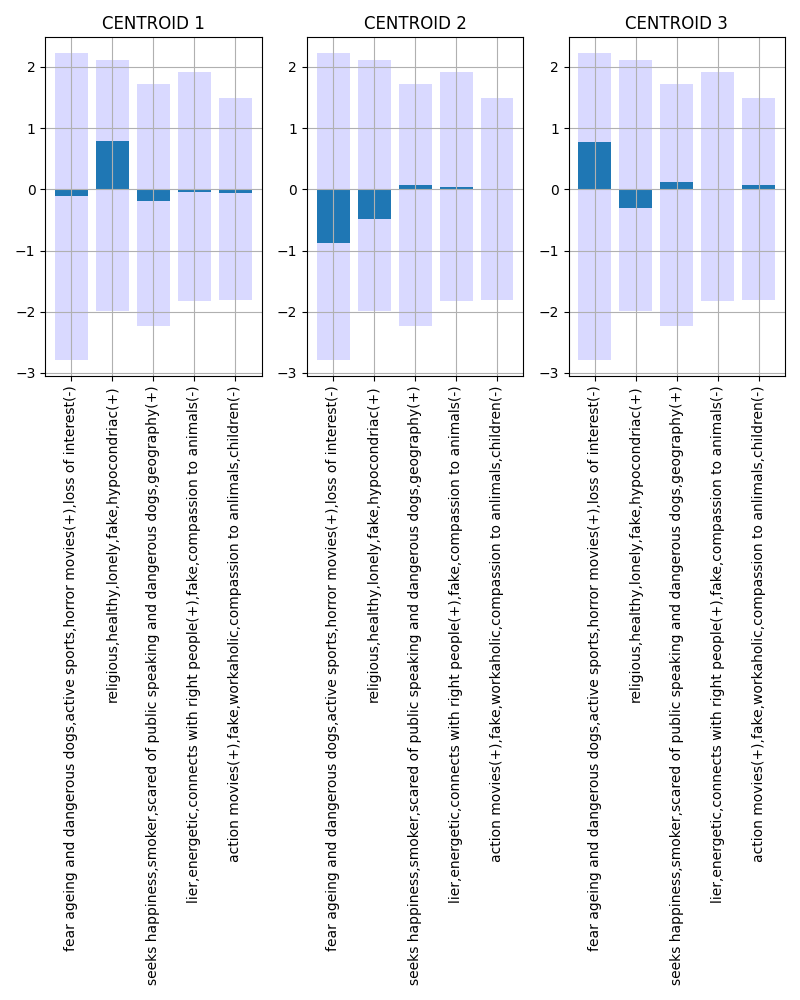

In [49]:
# min max scaled data
# COMPUTE THE MAX/MIN VALUES IN THE PC-SPACE
maxs_y = Y_mm.max(axis=0)  
mins_y = Y_mm.min(axis=0) 

# MAKE THE BARPLOTS OF THE CENTROIDS (WHAT DS DID)
fig_centroids, ax_centroids = plt.subplots(1, 3, figsize=(8, 10))
for ii in range(k_mm):
    ax_centroids[ii].bar(np.arange(km_mm.cluster_centers_.shape[1]), maxs_y, color='blue', alpha=0.15)
    ax_centroids[ii].bar(np.arange(km_mm.cluster_centers_.shape[1]), mins_y, color='blue', alpha=0.15)
    ax_centroids[ii].bar(np.arange(km_mm.cluster_centers_.shape[1]), km_mm.cluster_centers_[ii, :])
    ax_centroids[ii].set_xticks(ticks=np.arange(km_mm.cluster_centers_.shape[1]))
    ax_centroids[ii].set_xticklabels(labels=pc_names_mm, rotation=90)
    ax_centroids[ii].grid(visible=True, which='both')
    plt.tight_layout()
    ax_centroids[ii].set_title(f'CENTROID {ii+1}')
    #plt.tight_layout()

As previously forseen, for min max scaled data too the 3rd PC has a very low relevance in the clustering formation,while PC4 and PC5 do not contribute at all.

We can observe that:
- Centroid 1 is characterized by positive values of PC2

- Centroid 2 is characterized by negative values of PC1 and PC2

- Centroid 3 is characterized by positive values of PC1 and negative of PC2 (very small contribution)

We see that Centroid 2 shows opposite characteristics wrt Centroid 3.

Similarly to std data, the points are all distributed in one "central cloud" around the origin in the 2D space of the first two PCs, and do not create well separated groups of points; The consequence is that, as we expected from the PCA results, the first three PCs are not able to show the presence of patterns in the data.

Centroids interpretation:
- Centroid 1 is characterized by the values of PC2 : God, health, lonelyness,hypocondriac(+) are positively contributing feature.
- Centroid 2 is characterized by the opposite of PC1 and PC2: fear ageing and dangerous dogs, active sports, horror movies, God, loneliness(-) are negatively contributing feature, loss of interest(+) is a positively contributing feature.
- Centroid 3 is characterized by the values of PC1 : fear of ageing and dangerous dogs, active sports, horror movies(+) are positively contributing features, loss of interest(-) is a negatively contributing feature.

In [50]:
# LIST OF THE NAMES ASSIGNED TO THE FOUR CLUSTERS
cluster_names_mm =  ['religious,healthy,lonely,fake,hypocondriac(+)',
                     'fears ageing and dangerous dogs,active sports,horror movies,religious,lonely(-),loss of interest(+)',  
                    'fears ageing and dangerous dogs,active sports,horror movies(+),loss of interest(-)'
                 ]

Making a comparison with the Centroids obtained with standardized data, it is interesting to notice that some high contributing features are recurrent in both the datasets centroids: 
- it is the case for active sports and loss of interest : for Centroid 2 of std data and Centroid 3 of min max scaled data these are respectively a positively and a negatively contributing feature, while for Centroid 1 of std data and Centroid 2 of min max scaled data it is the opposite. Similarly, the God feature contributes positively to C1 of std data and to C1 of mm data and negatively to C3 of std data and to C2 of mm data.
- in both cases the feature category Phobias is a central one to discriminate between PCs and so between clusters; the most recurrent ones are fear of snakes and spiders (C1 of std), of ageing and of dangerous dogs (C2 and C3 of mm data).

We expect the similarities between clusters to also emerge in the interpretation of the clusters wrt some labels in the following exercise.

## Exercise 5. Cluster Evaluations

In the cells below, do the following operations:
1. For each one of the two datasets (_std_ and _mm_), perform an **external evaluation** of the clustering obtained at exercise 4.1 with respect to one or more labels in the list _labels_. **Comment the results, comparing the evaluation with the interpretation you gave at exercise 4.3**. 
2. For each one of the two datasets (_std_ and _mm_), perform an **internal evaluation** of each cluster, with respect to the silohuette score. **Comment the results**. 

### External evaluation

#### 5.1 For each one of the two datasets (_std_ and _mm_), perform an external evaluation of the clustering obtained at exercise 4.1 with respect to one or more labels in the list _labels_. Comment the results, comparing the evaluation with the interpretation you gave at exercise 4.3.

Let's see how data is distributed in the clusters, making a comparison wrt different labels. The bar plots represent the distribution of the ground truth labels within each KMeans cluster. They help identify how well the clustering aligns with the external labels: If a cluster has mostly data corresponding to one label response (e.g. all males or all females), the clustering has good alignment with that label (ex. Gender). If a cluster contains a mix of responses for that label, it might mean that the clustering doesn't strongly separate samples by that category.
It also gives an intuitive understanding of the composition of each cluster.

To have a higher comprehension of the goodness of the clusters for each label, we will check the following external cluster evaluation metrics:
- Homogeneity: Homogeneity close to 1 means clusters are pure (contain mostly one class).
- Completeness: Completeness close to 1 means all members of the same class are in the same cluster.
- ARI: This score adjusts for random chance and is robust even for imbalanced datasets. A value of 1 indicates perfect clustering alignment with ground truth, while 0 indicates random clustering.

The evaluation will be done on both the standardized and min max scaled dataset.

********evaluation metric results for standardized data*******
Homogeneity Score: 0.3069
Completeness Score: 0.1926
Adjusted Rand Index (ARI): 0.2657

********evaluation metric results for min max scaled data*******
Homogeneity Score: 0.3602
Completeness Score: 0.2258
Adjusted Rand Index (ARI): 0.2904


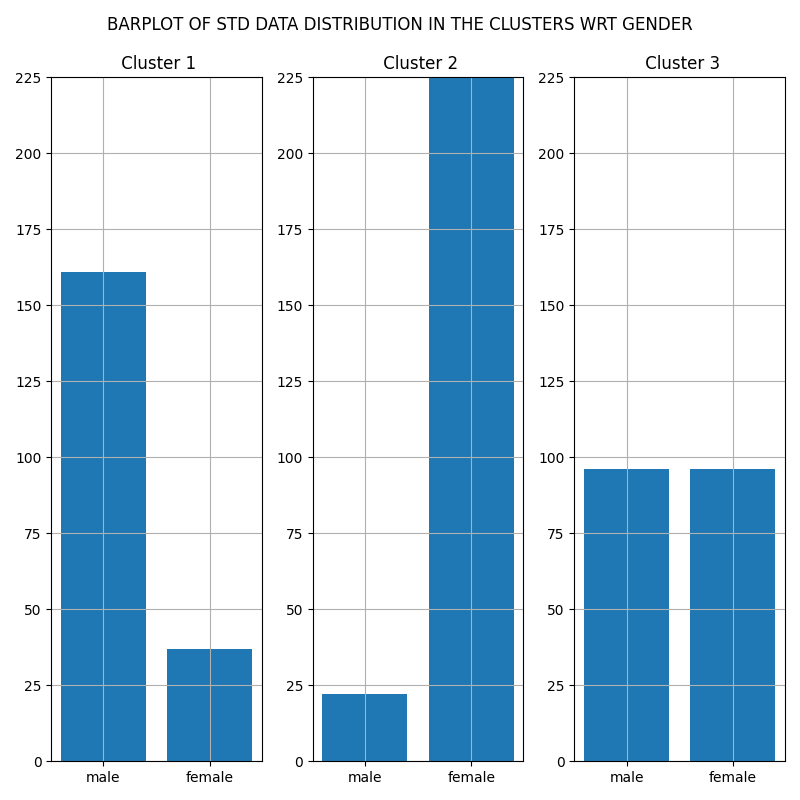

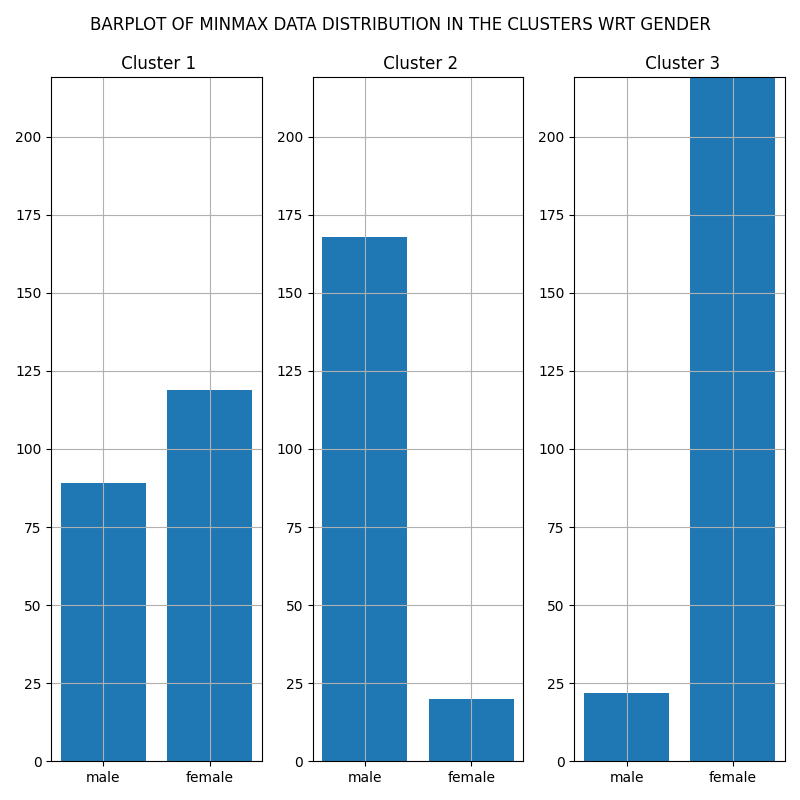

In [51]:
# EXTERNAL EVALUATION : GENDER
bin_labels = ['male', 'female']

mask_clusters_std = [km_std.labels_ == ii for ii in range(k_std)]
mask_clusters_mm = [km_mm.labels_ == ii for ii in range(k_mm)]
cluster_std = [dict(X_df_nonenc.loc[mask_clusters_std[ii], 'Gender'].value_counts()) for ii in range(k_std)]
cluster_mm = [dict(X_df_nonenc.loc[mask_clusters_mm[ii], 'Gender'].value_counts()) for ii in range(k_mm)]

maxcount_std = np.max([max(cluster_std[kk].values()) for kk in range(k_std)])
maxcount_mm = np.max([max(cluster_mm[kk].values()) for kk in range(k_mm)])

# Barplots of the clusters for std data
fig_centroids_ext_std, ax_centroids_ext_std = plt.subplots(1,3, figsize=(8, 8))
for ii in range(k_std):
    ax_centroids_ext_std[ii].bar(bin_labels, [cluster_std[ii].get(bb, 0) for bb in bin_labels])
    ax_centroids_ext_std[ii].set_ylim(0, maxcount_std)
    ax_centroids_ext_std[ii].grid(visible=True, which='both')
    plt.tight_layout(rect=[0, 0, 1, 0.95])
    ax_centroids_ext_std[ii].set_title(f' Cluster {ii+1}')
fig_centroids_ext_std.suptitle('BARPLOT OF STD DATA DISTRIBUTION IN THE CLUSTERS WRT GENDER')

# Barplots of the clusters for minmax scaled data
fig_centroids_ext_mm, ax_centroids_ext_mm = plt.subplots(1,3, figsize=(8, 8))
for ii in range(k_mm):
    ax_centroids_ext_mm[ii].bar(bin_labels, [cluster_mm[ii].get(bb, 0) for bb in bin_labels])
    ax_centroids_ext_mm[ii].set_ylim(0, maxcount_mm)
    ax_centroids_ext_mm[ii].grid(visible=True, which='both')
    plt.tight_layout(rect=[0, 0, 1, 0.95])
    ax_centroids_ext_mm[ii].set_title(f' Cluster {ii+1}')
fig_centroids_ext_mm.suptitle('BARPLOT OF MINMAX DATA DISTRIBUTION IN THE CLUSTERS WRT GENDER')

# Ground truth labels (Gender column from your dataset)
true_labels = X_df_nonenc['Gender']
# Predicted labels from KMeans
predicted_labels_std = km_std.labels_
predicted_labels_mm = km_mm.labels_

# Calculate external evaluation metrics
homogeneity_std = homogeneity_score(true_labels, predicted_labels_std)
homogeneity_mm = homogeneity_score(true_labels, predicted_labels_mm)

completeness_std = completeness_score(true_labels, predicted_labels_std)
completeness_mm = completeness_score(true_labels, predicted_labels_mm)

ari_std = adjusted_rand_score(true_labels, predicted_labels_std)
ari_mm = adjusted_rand_score(true_labels, predicted_labels_mm)


# Print the evaluation results
print('********evaluation metric results for standardized data*******')
print(f"Homogeneity Score: {homogeneity_std:.4f}")
print(f"Completeness Score: {completeness_std:.4f}")
print(f"Adjusted Rand Index (ARI): {ari_std:.4f}")
print('')
print('********evaluation metric results for min max scaled data*******')
print(f"Homogeneity Score: {homogeneity_mm:.4f}")
print(f"Completeness Score: {completeness_mm:.4f}")
print(f"Adjusted Rand Index (ARI): {ari_mm:.4f}")

Recall the clusters names for better understanding the interpretation: 

cluster_names_std =  
- C1 : 'active sports, good dreams, afraid of snakes and spiders(-), loss of interest(+)'
- C2 : 'active sports, God, borrowed stuff(+), loss of interest(-) '
- C3 : 'religious, healthy, adrenalinic sports, celebrities (-)'
                 
cluster_names_mm =
- C1 : 'religious,healthy,lonely,fake,hypocondriac(+)'
- C2 : 'fears ageing and dangerous dogs,active sports,horror movies,religious,lonely(-),loss of interest(+)'  
- C3 : 'fears ageing and dangerous dogs,active sports,horror movies(+),loss of interest(-)'
                 
The obtained clusters seem to align with the external Gender label for both datasets:
- in the case of the standardized data, Cluster 1 mainly contains males and Cluster 2 is mainly composed of females, while the third cluster does not seem to reflect a separation by gender. Using the centroids names it is possible to give an interpretation: males do not seem to like active sports and are not afraid of snakes and spiders and they lose interest quickly; the opposite could be stated for females, being Cluster 2's most contributing features the inverse ones. This interpretation is coherent with the previous interpretation of the Pcs in ex 3.4.
- in the case of min max scaled data, Cluster 2 is mainly composed of males, while Cluster 3 contains ainly females and Cluster 1 shows an homogeneous distrubution of the two labels. The possible interpretation derived from the ceentroids names is the following: males do not fear ageing and dangerous dogs, do not like active sports, are not religious and lose interest quickly. Again, being Centroid 3 characterized by the same features but with opposite contributions, the inverse could be stated for females. The interpretation aligns with the previous one of ex. 3.4
- for both datasets, the centroid where the labels are more homogeneously distributed is the one which does not present opposite characteristics wrt another cluster; this is probably due to the fact that features contributing the most to these clusters do not reflect a pattern in the data that helps to discriminate wrt gender.

The satisfying dividion of datat wrt Gender is also highlighted by the external evaluation metrics score obtained for this label; it is the only one for which the values of the metrics are higher than 1e-2. Nonetheless, the metrics values are not very close to 1, meaning that the separation is not excellent.

********evaluation metric results for standardized data*******
Homogeneity Score: 0.0244
Completeness Score: 0.0517
Adjusted Rand Index (ARI): 0.0046

********evaluation metric results for min max scaled data*******
Homogeneity Score: 0.0139
Completeness Score: 0.0294
Adjusted Rand Index (ARI): 0.0022


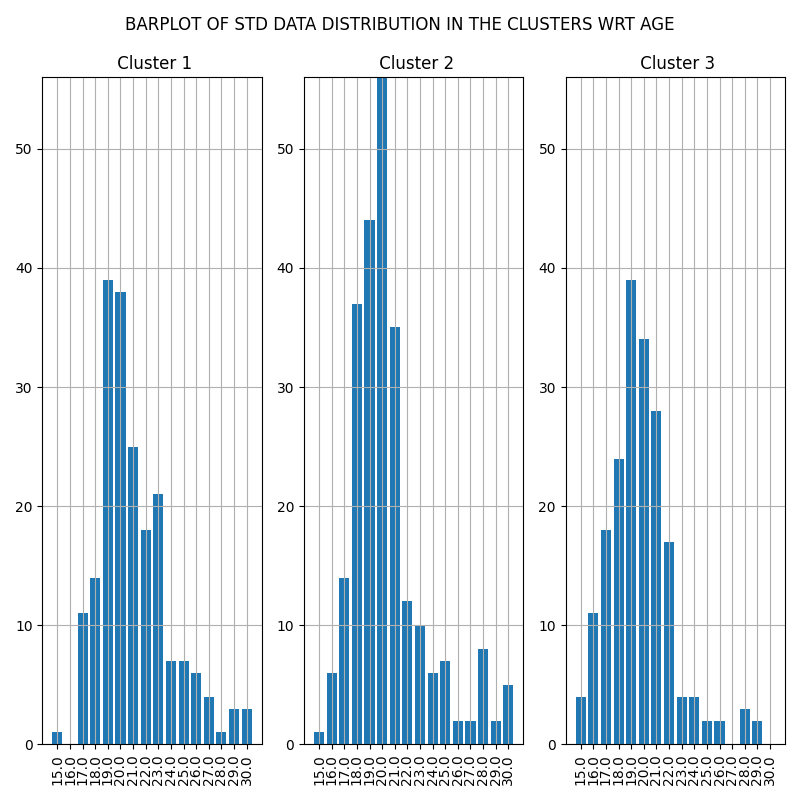

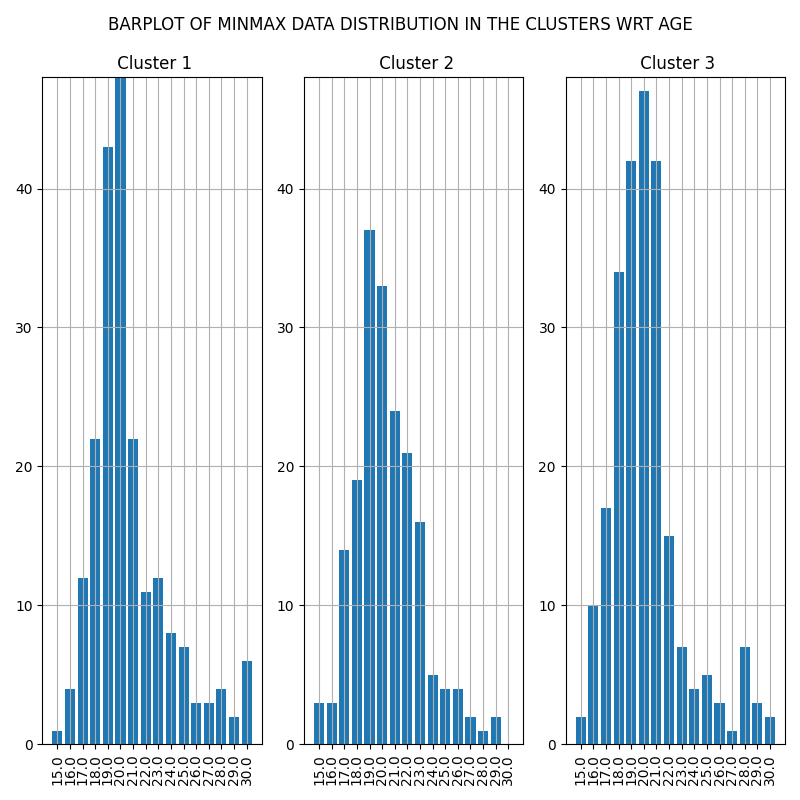

In [52]:
# EXTERNAL EVALUATION : AGE
bin_labels = age

mask_clusters_std = [km_std.labels_ == ii for ii in range(k_std)]
mask_clusters_mm = [km_mm.labels_ == ii for ii in range(k_mm)]
cluster_std = [dict(X_df_nonenc.loc[mask_clusters_std[ii], 'Age'].value_counts()) for ii in range(k_std)]
cluster_mm = [dict(X_df_nonenc.loc[mask_clusters_mm[ii], 'Age'].value_counts()) for ii in range(k_mm)]

maxcount_std = np.max([max(cluster_std[kk].values()) for kk in range(k_std)])
maxcount_mm = np.max([max(cluster_mm[kk].values()) for kk in range(k_mm)])

# Barplots of the clusters for std data
fig_centroids_ext_std, ax_centroids_ext_std = plt.subplots(1,3, figsize=(8, 8))
for ii in range(k_std):
    ax_centroids_ext_std[ii].bar(bin_labels, [cluster_std[ii].get(bb, 0) for bb in bin_labels])
    ax_centroids_ext_std[ii].set_ylim(0, maxcount_std)
    ax_centroids_ext_std[ii].grid(visible=True, which='both')
    plt.tight_layout(rect=[0, 0, 1, 0.95])
    ax_centroids_ext_std[ii].set_title(f' Cluster {ii+1}')
    ax_centroids_ext_std[ii].set_xticks(ticks=age)
    ax_centroids_ext_std[ii].set_xticklabels(labels=bin_labels, rotation=90)
fig_centroids_ext_std.suptitle('BARPLOT OF STD DATA DISTRIBUTION IN THE CLUSTERS WRT AGE')

# Barplots of the clusters for minmax scaled data
fig_centroids_ext_mm, ax_centroids_ext_mm = plt.subplots(1,3, figsize=(8, 8))
for ii in range(k_mm):
    ax_centroids_ext_mm[ii].bar(bin_labels, [cluster_mm[ii].get(bb, 0) for bb in bin_labels])
    ax_centroids_ext_mm[ii].set_ylim(0, maxcount_mm)
    ax_centroids_ext_mm[ii].grid(visible=True, which='both')
    plt.tight_layout(rect=[0, 0, 1, 0.95])
    ax_centroids_ext_mm[ii].set_title(f' Cluster {ii+1}')
    ax_centroids_ext_mm[ii].set_xticks(ticks=age)
    ax_centroids_ext_mm[ii].set_xticklabels(labels=bin_labels, rotation=90)
fig_centroids_ext_mm.suptitle('BARPLOT OF MINMAX DATA DISTRIBUTION IN THE CLUSTERS WRT AGE')

# Ground truth labels (Gender column from your dataset)
true_labels = X_df_nonenc['Age']
# Predicted labels from KMeans
predicted_labels_std = km_std.labels_
predicted_labels_mm = km_mm.labels_

# Calculate external evaluation metrics
homogeneity_std = homogeneity_score(true_labels, predicted_labels_std)
homogeneity_mm = homogeneity_score(true_labels, predicted_labels_mm)

completeness_std = completeness_score(true_labels, predicted_labels_std)
completeness_mm = completeness_score(true_labels, predicted_labels_mm)

ari_std = adjusted_rand_score(true_labels, predicted_labels_std)
ari_mm = adjusted_rand_score(true_labels, predicted_labels_mm)

# Print the evaluation results
print('********evaluation metric results for standardized data*******')
print(f"Homogeneity Score: {homogeneity_std:.4f}")
print(f"Completeness Score: {completeness_std:.4f}")
print(f"Adjusted Rand Index (ARI): {ari_std:.4f}")
print('')
print('********evaluation metric results for min max scaled data*******')
print(f"Homogeneity Score: {homogeneity_mm:.4f}")
print(f"Completeness Score: {completeness_mm:.4f}")
print(f"Adjusted Rand Index (ARI): {ari_mm:.4f}")

In both cases, no clusters aligns with the external label Age, meaning that clusters do not separate well data wrt to the age group the belong to. This result can be explained by the fact that the most contributing features for each cluster do not underly a pattern that could be relied to an age group. The same absence of separartion in the data wrt Age was already clear from the score graphs of ex. 3.4.

The very low scores of the external evaluation metrics computed for the Age label reflects the previous results.

********evaluation metric results for standardized data*******
Homogeneity Score: 0.0002
Completeness Score: 0.0001
Adjusted Rand Index (ARI): -0.0024

********evaluation metric results for min max scaled data*******
Homogeneity Score: 0.0123
Completeness Score: 0.0068
Adjusted Rand Index (ARI): 0.0068


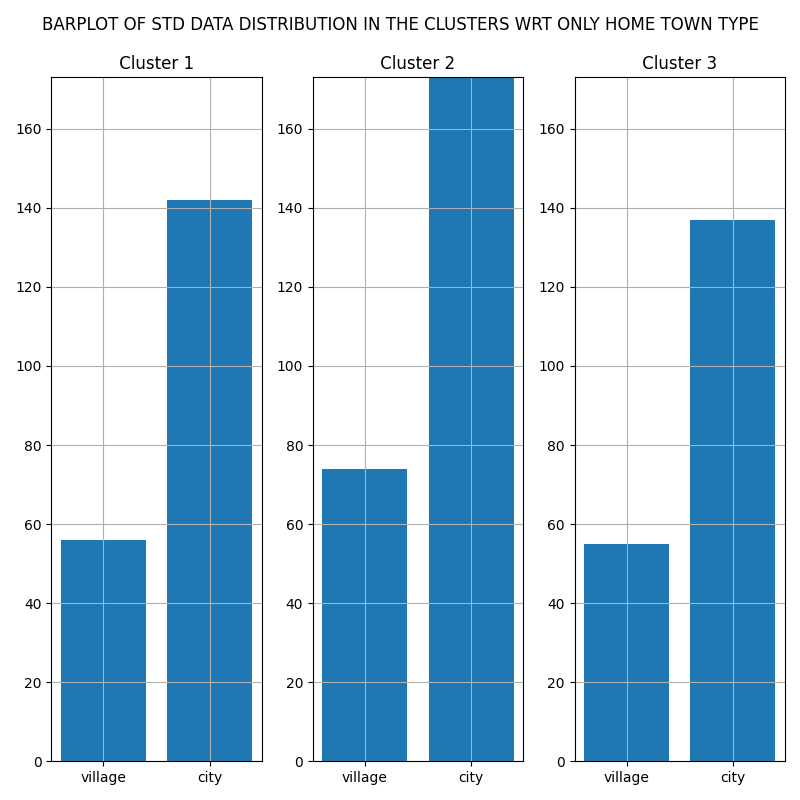

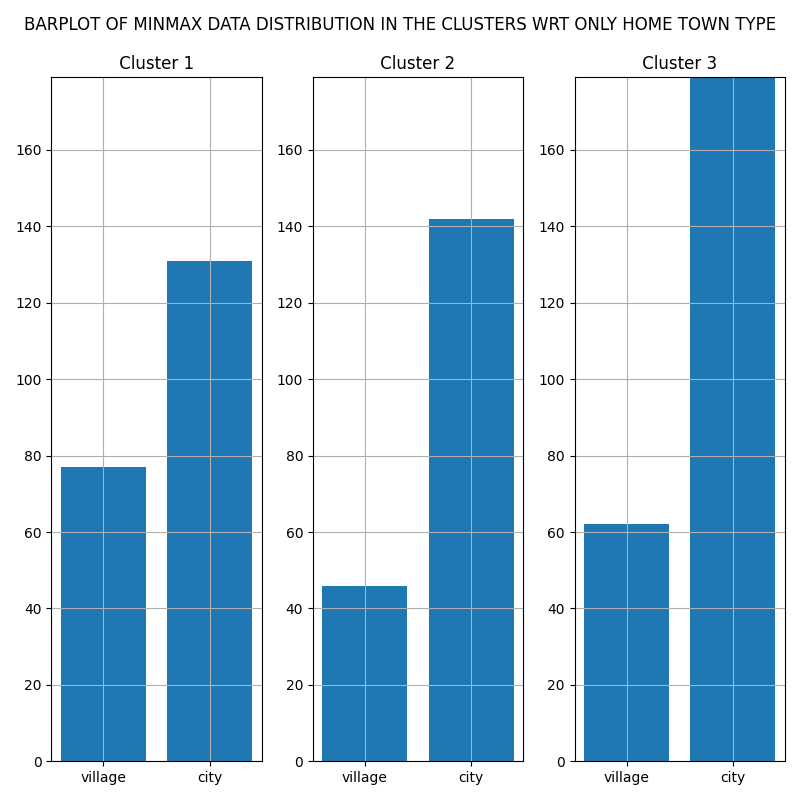

In [53]:
# EXTERNAL EVALUATION : HOME TOWN TYPE
bin_labels = ['village', 'city']

mask_clusters_std = [km_std.labels_ == ii for ii in range(k_std)]
mask_clusters_mm = [km_mm.labels_ == ii for ii in range(k_mm)]
cluster_std = [dict(X_df_nonenc.loc[mask_clusters_std[ii], 'Home Town Type'].value_counts()) for ii in range(k_std)]
cluster_mm = [dict(X_df_nonenc.loc[mask_clusters_mm[ii], 'Home Town Type'].value_counts()) for ii in range(k_mm)]

maxcount_std = np.max([max(cluster_std[kk].values()) for kk in range(k_std)])
maxcount_mm = np.max([max(cluster_mm[kk].values()) for kk in range(k_mm)])

# Barplots of the clusters for std data
fig_centroids_ext_std, ax_centroids_ext_std = plt.subplots(1,3, figsize=(8, 8))
for ii in range(k_std):
    ax_centroids_ext_std[ii].bar(bin_labels, [cluster_std[ii].get(bb, 0) for bb in bin_labels])
    ax_centroids_ext_std[ii].set_ylim(0, maxcount_std)
    ax_centroids_ext_std[ii].grid(visible=True, which='both')
    plt.tight_layout(rect=[0, 0, 1, 0.95])
    ax_centroids_ext_std[ii].set_title(f' Cluster {ii+1} ')
fig_centroids_ext_std.suptitle('BARPLOT OF STD DATA DISTRIBUTION IN THE CLUSTERS WRT ONLY HOME TOWN TYPE')

# Barplots of the clusters for minmax scaled data
fig_centroids_ext_mm, ax_centroids_ext_mm = plt.subplots(1,3, figsize=(8, 8))
for ii in range(k_mm):
    ax_centroids_ext_mm[ii].bar(bin_labels, [cluster_mm[ii].get(bb, 0) for bb in bin_labels])
    ax_centroids_ext_mm[ii].set_ylim(0, maxcount_mm)
    ax_centroids_ext_mm[ii].grid(visible=True, which='both')
    plt.tight_layout(rect=[0, 0, 1, 0.95])
    ax_centroids_ext_mm[ii].set_title(f' Cluster {ii+1} ')
fig_centroids_ext_mm.suptitle('BARPLOT OF MINMAX DATA DISTRIBUTION IN THE CLUSTERS WRT ONLY HOME TOWN TYPE')


# Ground truth labels (Gender column from your dataset)
true_labels = X_df_nonenc['Home Town Type']
# Predicted labels from KMeans
predicted_labels_std = km_std.labels_
predicted_labels_mm = km_mm.labels_

# Calculate external evaluation metrics
homogeneity_std = homogeneity_score(true_labels, predicted_labels_std)
homogeneity_mm = homogeneity_score(true_labels, predicted_labels_mm)

completeness_std = completeness_score(true_labels, predicted_labels_std)
completeness_mm = completeness_score(true_labels, predicted_labels_mm)

ari_std = adjusted_rand_score(true_labels, predicted_labels_std)
ari_mm = adjusted_rand_score(true_labels, predicted_labels_mm)

# Print the evaluation results
print('********evaluation metric results for standardized data*******')
print(f"Homogeneity Score: {homogeneity_std:.4f}")
print(f"Completeness Score: {completeness_std:.4f}")
print(f"Adjusted Rand Index (ARI): {ari_std:.4f}")
print('')
print('********evaluation metric results for min max scaled data*******')
print(f"Homogeneity Score: {homogeneity_mm:.4f}")
print(f"Completeness Score: {completeness_mm:.4f}")
print(f"Adjusted Rand Index (ARI): {ari_mm:.4f}")

The label Home Town Type represents another example of the inability of our clustering division to separate data wrt a label different from Gender. For both datasets, the three clusters contain a mix of responses for the label, which gives an intuition of the composition of each cluster, but reflects the fact that the clustering doesn't strongly separate samples by Home Town Type. 

A mathematical proof of this lack of separation is given by the very low (almost zero) scores of the external evaluation metrics computed for the label.

### Internal evaluation
#### 5.2 For each one of the two datasets (_std_ and _mm_), perform an internal evaluation of each cluster, with respect to the silohuette score. Comment the results. 

*********Silhouette coefficient per cluster and overall for standardized data**********


,Sil. score
"active sports, good dreams, afraid of snakes and spiders(-), loss of interest(+)",0.158739
"active sports, God, borrowed stuff(+), loss of interest(-)",0.175412
"religious, healthy, adrenalinic sports, celebrities (-)",0.163280
Global,0.166573


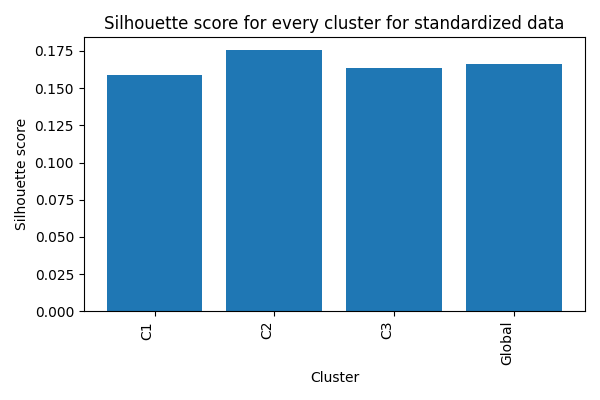

In [54]:
# standardized data
silscores_std = silhouette_samples(Y_std, km_std.labels_)
cluster_silscores_std = [np.mean(silscores_std[km_std.labels_ == kk ]) for kk in range(k_std)]
print('*********Silhouette coefficient per cluster and overall for standardized data**********')
display(pd.DataFrame(np.array(cluster_silscores_std + [np.max(silcoeff_list_std)]), index=cluster_names_std + ['Global'], columns=['Sil. score']))
#bar plots of silhouette scores
plt.figure(figsize=(6, 4))
plt.bar(np.arange(k_std+1), cluster_silscores_std + [np.max(silcoeff_list_std)] )
plt.title('Silhouette score for every cluster for standardized data')
plt.ylabel('Silhouette score')
plt.xlabel('Cluster')
plt.xticks(ticks=np.arange(k_std+1),
        labels=['C1', 'C2', 'C3'] + ['Global'],
        rotation=90, ha='right')
plt.tight_layout()
plt.show()

The silhouette scores for all clusters, as well as the global score, are relatively low (all are below 0.2). This suggests that the clusterings are well-defined, as we expected from the previous external evaluation. The low silhouette scores reflect the fact that the data points within clusters are not tightly grouped or are not well-separated from other clusters.

Cluster 2 (active sports, God, borrowed stuff(+), loss of interest(-)) has the highest silhouette score (0.1754), indicating that this cluster is slightly better defined compared to the others. Cluster 1 (active sports, good dreams, afraid of snakes and spiders(-), loss of interest(+)) has the lowest silhouette score (0.1587), which indicates poor cohesion or separation for this cluster.

*********Silhouette coefficient per cluster and overall for minmax scaled data**********


,Sil. score
"religious,healthy,lonely,fake,hypocondriac(+)",0.150876
"fears ageing and dangerous dogs,active sports,horror movies,religious,lonely(-),loss of interest(+)",0.213593
"fears ageing and dangerous dogs,active sports,horror movies(+),loss of interest(-)",0.196783
Global,0.186754


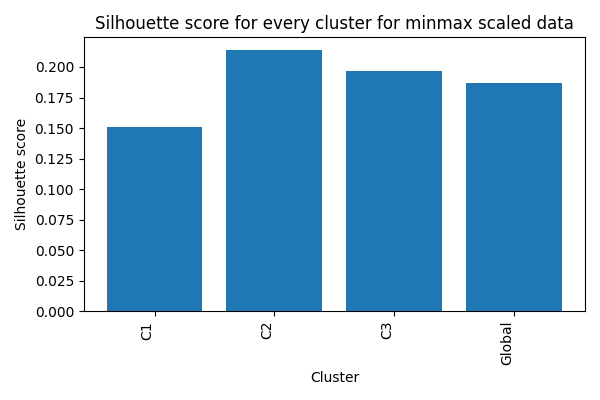

In [55]:
# minmax scaled data
silscores_mm = silhouette_samples(Y_mm, km_mm.labels_)
cluster_silscores_mm = [np.mean(silscores_mm[km_mm.labels_ == kk ]) for kk in range(k_mm)]
print('*********Silhouette coefficient per cluster and overall for minmax scaled data**********')
display(pd.DataFrame(np.array(cluster_silscores_mm + [np.max(silcoeff_list_mm)]), index=cluster_names_mm + ['Global'], columns=['Sil. score']))

#bar plots of silhouette scores
plt.figure(figsize=(6, 4))
plt.bar(np.arange(k_mm+1), cluster_silscores_mm + [np.max(silcoeff_list_mm)])
plt.title('Silhouette score for every cluster for minmax scaled data')
plt.ylabel('Silhouette score')
plt.xlabel('Cluster')
plt.xticks(ticks=np.arange(k_mm+1),
        labels=['C1', 'C2', 'C3'] + ['Global'],
        rotation=90, ha='right')
plt.tight_layout()
plt.show()

The same considerations can be done also for the min max scaled dataset, for which the lows of the silhouette scores are again low. Nonetheless, they are slightly higher rìthan the previous ones, indicating a slightly better clustering division. 

Cluster 2 (fears ageing and dangerous dogs,active sports,horror movies,religious,lonely(-),loss of interest(+)) has the highest silhouette score (0.2136), indicating that this cluster is better defined compared to the others. Cluster 1 (religious,healthy,lonely,fake,hypocondriac(+)) has the lowest silhouette score (0.1508), which indicates poor cohesion or separation for this cluster.

# Conclusions
The conducted data analysis could be an example of the the real-world task of summarising the information contained in the dataset with a low number of features, still maintaining some amount of information. Unluckyly, the analysis results are not very useful to have a deep comprehension of the dataset. 

Concerning the PCA performance, the explained variance of the first 5 Principal Components is less than 33%, meaning that dimensionality reduction caused the loss of a big amount of infomation. As a consequence, the PCA analysis did not allow to reveal interesting patterns inside the dataframe, as it is clear from the obtained score graphs with respect to the external labels. The only exception is represented by the Gender label, for which the conducted study allowed to understand some of the most common answers to the survey questions for males and females.

The application of the Kmeans clustering techinique highlighted the same problem : the dataset is not easily interpretable or separable into groups that represent some label separation. It is evident from the clusters plot, where data is all concentrated around a central cloud and there are no distinguishable groups. This intuition was confirmed by means of the silhouette score at the internal evaluation step.

In conclusion, the conducted analisys did not alow to recognise defined patterns in the data nor to separate them in a meaninfgul way. Despite that, there is room for improvement. Better results could be obtained by considering a larger number of Principal Components, in such a way that the amount of information contained in them is larger. Another idea could be to repeat the analysis by selecting only a subset of features: for example, those belonging to just one or two cathegories, or a subset of features sharing some common aspects or applications, in order to make an analisys that is more focued on investigating a specific topic. 